# Phase 4 — Deploy three-phase learning to Wells 1, 2, 3, 5 and 8

**Inference only.** Reuse the Phase 1 physics-guided neural network, Phase 2 deterministic lithology rules, and Phase 3 trained fluid classifier from the saved **Three_Phase_Learned_Bundle**. No fitting/retraining.

**Important:** The 1.5 m reservoir interval constraint is evaluated in MD metres, as in Phase 3; it is not true stratigraphic thickness. Unknown (-1) values may optionally be filled by nearest neighbour **after** thickness filtering, as in the latest Phase 3 workflow. These filled classes are explicitly flagged.

**Well 3:** No checkshot → derive TWT by integrating measured DTC over valid intervals; use an average checkshot time–depth relationship from the other wells where DTC is unavailable, smooth transition zones, and check monotonicity. No markers → missing marker distances and all-zero marker identity features; no invented ties.

**Stop on unknown datum/units rather than silently guessing.** Inspect discovery, time-depth QC and missing-curve diagnostics before interpreting output. No final composites are used for inference.

**Confirmed new-well KB elevations:** Well 1 = 9.45 m; Well 2 = 22.0 m; Well 3 = 22.0 m; Well 5 = 22.0 m; Well 8 = 29.8 m. **Well 3 DTC:** µs/ft. These are preconfigured in Cell 2.

In [80]:
from pathlib import Path
import re, json, warnings, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lasio, joblib, torch
from torch import nn
from scipy.ndimage import gaussian_filter1d
from IPython.display import display
from matplotlib.colors import ListedColormap, BoundaryNorm
print('Phase 4 environment:', 'PyTorch', torch.__version__)

Phase 4 environment: PyTorch 2.13.0+cu129


In [81]:
# Cell 2 — EDITABLE deployment settings
ROOT = Path('/home/apgce_team_08/link-to-apgce_team_08')
INPUT_ROOT = ROOT/'Well_To_Predict'
WELL_NAMES = ['Well_1','Well_2','Well_3','Well_5','Well_8']
OUTPUT_ROOT = ROOT/'Well_To_Predict_Phase4_Output'
BUNDLE = ROOT/'Well_4_6_7_Phase3_FluidReservoir_Output'/'Three_Phase_Learned_Bundle'
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

# If all five wells' LAS/TXT files are directly in INPUT_ROOT, leave folder overrides blank.
# For nested folders, auto-discovery finds Well_1, Well-1, Well1 etc.
WELL_FOLDER_OVERRIDES = {} # e.g. {'Well_1': INPUT_ROOT/'Well-1'}
FILE_OVERRIDES = {} # e.g. {'Well_2':{'raw':'Well-2.las','checkshot':'Well-2_Checkshot.txt'}}
CURVE_ALIASES = {} # e.g. {'Well_3':{'DTC':'DTC_P','GR':'GR_P'}}, after verifying definitions
# REQUIRED if not independently inferable from trustworthy marker MDKB/TVDSS ties or LAS elevation.
# TVDSS = TVD - datum. NEVER copy the training wells' datums to these wells.
DATUM_OVERRIDES_M = {
    'Well_1': 9.45,
    'Well_2': 22.0,
    'Well_3': 22.0,
    'Well_5': 22.0,
    'Well_8': 29.8,
} # User-provided KB elevations (m); TVDSS = TVD - KB elevation
ALLOW_LAS_KB_ELEVATION = True
ALLOW_MARKER_DATUM_INFERENCE = True
DEPTH_TOLERANCE_M = 0.10
INFERENCE_BATCH = 4096

# Checkshot format: column 1 TVDSS (m), column 2 TWT (ms), as training notebook.
# If any new well differs, reformat the file or modify the reader deliberately.
CHECKSHOT_TWT_UNIT = 'ms'
DTC_CURVE_CANDIDATES = ('DTC_P','DTC','DTCO','DT','AC')
DTC_UNIT_OVERRIDE = {'Well_3': 'us/ft'} # User-confirmed sonic slowness unit
DTC_MIN_USFT = 35.0
DTC_MAX_USFT = 400.0
DTC_MAX_INTERPOLATION_GAP_M = 1.0
DTC_TRANSITION_SMOOTH_M = 8.0 # Gaussian smoothing of TWT gradient across DTC/reference transitions
DTC_MIN_VALID_SAMPLES = 30
AVERAGE_TD_REFERENCE_WELLS = ['Well_4','Well_6','Well_7'] # plus target wells with checkshots
AVERAGE_TD_INCLUDE_TARGET_CHECKSHOTS = True
REFERENCE_STEP_M = 1.0
REFERENCE_MIN_SUPPORT = 1
REFERENCE_EXTRAPOLATION_MAX_M = 300.0 # controlled extrapolation by end gradients
REFERENCE_DEPTH_SMOOTH_M = 8.0
DTC_ANCHOR_TVDSS_M = None # default: middle of valid Well 3 log depth

# Keep Phase 3 learned thresholds and class mapping from bundle by default.
FILL_UNKNOWN_NEAREST = True
FILL_UNKNOWN_ON_RULE_AND_ML = True
EXPORT_PLOTS = True
PLOT_MAX_SAMPLES = 30000
PLOT_FONT = 15
print('Input:',INPUT_ROOT)
print('Bundle:',BUNDLE)

Input: /home/apgce_team_08/link-to-apgce_team_08/Well_To_Predict
Bundle: /home/apgce_team_08/link-to-apgce_team_08/Well_4_6_7_Phase3_FluidReservoir_Output/Three_Phase_Learned_Bundle


In [82]:
# Cell 3 — Load and verify all saved Phase 1/2/3 learning artifacts
required = ['Well4_6_7_PhysicsLossNN.pt',
            'Well4_6_7_PhysicsLossNN_Preprocessing.joblib',
            'PhysicsLossNN_Manifest.json',
            'Phase3_FluidClassifier.joblib',
            'Three_Phase_Learning_Manifest.json']
missing=[x for x in required if not (BUNDLE/x).is_file()]
if missing:
    raise FileNotFoundError(f'Missing bundle files: {missing}. Run Phase 3G in the latest Phase 3 notebook.')
package=json.loads((BUNDLE/'Three_Phase_Learning_Manifest.json').read_text())
p1manifest=json.loads((BUNDLE/'PhysicsLossNN_Manifest.json').read_text())
features=list(p1manifest['features'])
targets=list(p1manifest['targets'])
prep=joblib.load(BUNDLE/'Well4_6_7_PhysicsLossNN_Preprocessing.joblib') # trusted local artifact only
classifier=joblib.load(BUNDLE/'Phase3_FluidClassifier.joblib')
PHASE3_FEATURES=list(package['phase3']['features'])
PHASE3_RULES=dict(package['phase3']['rules'])
PHASE2_RULES=dict(package['phase2'])
PHYSICS_PARAMS=dict(package['well_processing']['physics_parameters'])
MARKER_VOCABULARY=list(package['well_processing']['marker_vocabulary'])
APPROVED_MARKER_MAPPING=dict(package['well_processing'].get('approved_marker_mapping',{}))
INPUTS=list(package['well_processing']['measured_inputs'])
EXPECTED_INPUTS=['RAW_'+c for c in INPUTS]
assert features[:len(EXPECTED_INPUTS)]==EXPECTED_INPUTS, 'Phase 1 input order mismatch'
assert len(features)==int(prep['imputer'].n_features_in_), 'Saved Phase 1 preprocessing feature mismatch'
if not hasattr(classifier,'predict_proba'): raise TypeError('Phase 3 classifier has no predict_proba')
if not set(classifier.classes_).issubset({0,1,2,3}):
    raise ValueError(f'Unexpected Phase 3 trained classes: {classifier.classes_}')
print('Phase 1 features:',len(features),'targets:',len(targets))
print('Phase 3 classes trained:',classifier.classes_)
print('Marker vocabulary:',len(MARKER_VOCABULARY),'(Well 3 will have none)')
print('Reservoir minimum thickness:',PHASE3_RULES.get('min_reservoir_thickness_m'),'m')
display(pd.DataFrame({'Phase1_feature':features}))

Phase 1 features: 49 targets: 20
Phase 3 classes trained: [0 1 2 3]
Marker vocabulary: 30 (Well 3 will have none)
Reservoir minimum thickness: 0 m


,Phase1_feature
0,RAW_CALI_P
1,RAW_DENS_P
2,RAW_GR_P
3,RAW_NEUT_P
4,RAW_NPHIHC
5,RAW_PEF_P
6,RAW_RHOBHC
7,RAW_RT_P
8,MARKER_DISTANCE_ABOVE_MS
9,MARKER_DISTANCE_BELOW_MS


In [83]:
# Cell 4 — Discover files, allowing absent deviation and Well 3 checkshot/markers
def norm_well(s):
    return re.sub(r'[^a-z0-9]','',str(s).lower())

def folder_for(well):
    if well in WELL_FOLDER_OVERRIDES: return Path(WELL_FOLDER_OVERRIDES[well])
    if not INPUT_ROOT.is_dir(): raise FileNotFoundError(INPUT_ROOT)
    dirs=[p for p in INPUT_ROOT.iterdir() if p.is_dir() and norm_well(p.name)==norm_well(well)]
    if len(dirs)==1:return dirs[0]
    if len(dirs)>1:raise ValueError(f'{well}: multiple matching folders: {dirs}')
    # flat-folder arrangement is also supported
    return INPUT_ROOT

def find_file(well,folder,kind):
    override=FILE_OVERRIDES.get(well,{}).get(kind)
    if override:
        p=Path(override);p=p if p.is_absolute() else folder/p
        if not p.is_file():raise FileNotFoundError(p)
        return p
    candidates=[p for p in folder.iterdir() if p.is_file() and
                (p.suffix.lower()==('.las' if kind=='raw' else '.txt'))]
    if kind=='raw':
        candidates=[p for p in candidates if 'composite' not in p.stem.lower()
                    and 'interp' not in p.stem.lower()]
    else:
        tokens={'checkshot':('checkshot','check_shot','check-shot','check shot'),
                'deviation':('deviation','deviat','survey'),
                'markers':('marker','tops')}[kind]
        candidates=[p for p in candidates if any(t in p.stem.lower() for t in tokens)]
    # Restrict flat-folder candidates by well number; avoid Well-1 matching Well-10.
    if folder==INPUT_ROOT:
        wnum=re.search(r'\d+',well).group()
        candidates=[p for p in candidates if re.search(
            rf'(?i)(?:^|[^a-z0-9])well[_\s-]*0*{wnum}(?!\d)(?:[^a-z0-9]|$)',p.stem)]
    if len(candidates)==1:return candidates[0]
    if not candidates and kind in ('deviation','markers'):return None
    if not candidates and kind=='checkshot' and well=='Well_3':return None
    raise ValueError(f'{well} {kind}: expected one file, found {[p.name for p in candidates]}; set FILE_OVERRIDES')

FILES={}
for well in WELL_NAMES:
    folder=folder_for(well)
    FILES[well]={'folder':folder,**{kind:find_file(well,folder,kind)
                 for kind in ('raw','checkshot','deviation','markers')}}
    if well!='Well_3' and FILES[well]['checkshot'] is None:
        raise ValueError(f'{well}: checkshot is required; only Well 3 uses DTC fallback')
display(pd.DataFrame({w:{k:str(v) if v is not None else 'NOT PROVIDED'
                         for k,v in x.items()} for w,x in FILES.items()}).T)

,folder,raw,checkshot,deviation,markers
Well_1,/home/apgce_team_08/link-to-apgce_team_08/Well...,/home/apgce_team_08/link-to-apgce_team_08/Well...,/home/apgce_team_08/link-to-apgce_team_08/Well...,NOT PROVIDED,/home/apgce_team_08/link-to-apgce_team_08/Well...
Well_2,/home/apgce_team_08/link-to-apgce_team_08/Well...,/home/apgce_team_08/link-to-apgce_team_08/Well...,/home/apgce_team_08/link-to-apgce_team_08/Well...,/home/apgce_team_08/link-to-apgce_team_08/Well...,/home/apgce_team_08/link-to-apgce_team_08/Well...
Well_3,/home/apgce_team_08/link-to-apgce_team_08/Well...,/home/apgce_team_08/link-to-apgce_team_08/Well...,NOT PROVIDED,NOT PROVIDED,NOT PROVIDED
Well_5,/home/apgce_team_08/link-to-apgce_team_08/Well...,/home/apgce_team_08/link-to-apgce_team_08/Well...,/home/apgce_team_08/link-to-apgce_team_08/Well...,/home/apgce_team_08/link-to-apgce_team_08/Well...,/home/apgce_team_08/link-to-apgce_team_08/Well...
Well_8,/home/apgce_team_08/link-to-apgce_team_08/Well...,/home/apgce_team_08/link-to-apgce_team_08/Well...,/home/apgce_team_08/link-to-apgce_team_08/Well...,NOT PROVIDED,/home/apgce_team_08/link-to-apgce_team_08/Well...


In [84]:
# Cell 5 — LAS / TXT parsing, consistent with Phase 1 training
def las_frame(path, well):
    las=lasio.read(str(path),engine='normal')  # works with wrapped LAS
    df=las.df().reset_index()
    df.columns=[str(c).strip().upper() for c in df.columns]
    df=df.rename(columns={df.columns[0]:'MDKB_m'})
    for c in df.columns:
        df[c]=pd.to_numeric(df[c],errors='coerce').replace([np.inf,-np.inf,-9999,-999.25,9999],np.nan)
    df=df.dropna(subset=['MDKB_m']).sort_values('MDKB_m').drop_duplicates('MDKB_m').reset_index(drop=True)
    for old,new in CURVE_ALIASES.get(well,{}).items():
        old,new=old.upper(),new.upper()
        if old in df and new not in df: df=df.rename(columns={old:new})
    units={str(c.mnemonic).strip().upper():str(c.unit).strip() for c in las.curves}
    return df,units

def numeric_rows(path,ncols):
    rows=[]
    for line in Path(path).read_text().splitlines():
        parts=line.split()
        if len(parts)<ncols or line.lstrip().startswith('#'):continue
        try:rows.append([float(x) for x in parts[:ncols]])
        except ValueError:continue
    a=np.asarray(rows,dtype=float)
    if a.ndim!=2 or len(a)<2:raise ValueError(f'Invalid numeric table: {path}')
    a=a[np.argsort(a[:,0])]
    if np.any(np.diff(a[:,0])<=0):raise ValueError(f'Duplicate or non-monotonic first column: {path}')
    return a

def read_markers(path):
    """Parse marker NAME MDKB TVDSS or NAME TVDSS; preserve partial rows.

    Column ordering must be checked if a well uses a different convention.
    """
    rows=[]; skipped=[]
    for line_number,line in enumerate(Path(path).read_text(errors='replace').splitlines(),1):
        line=line.strip()
        if not line or line.startswith(('#','~',';')): continue
        parts=re.split(r'[\t,;]+|\s{2,}',line)
        parts=[x.strip().strip('"') for x in parts if x.strip()]
        if len(parts)<2:parts=line.split()
        if len(parts)<2:continue
        # Accept a marker name containing spaces if separated by whitespace.
        if len(parts)>3:
            parts=[' '.join(parts[:-2]),parts[-2],parts[-1]]
        name=parts[0]
        try:
            if len(parts)>=3:
                md=float(parts[1]);tvdss=float(parts[2])
            else:
                md=np.nan;tvdss=float(parts[1])
            if np.isfinite(tvdss):rows.append((name,md,tvdss))
        except (ValueError,TypeError):
            skipped.append((line_number,line[:100]))
    out=pd.DataFrame(rows,columns=['Marker','MDKB_m','Marker_TVDSS_m'])
    print(f'Marker parser {Path(path).name}: {len(out)} rows, {len(skipped)} unparsed lines')
    if skipped:print('  Unparsed examples:',skipped[:4])
    if out.empty:print('  WARNING: no marker rows parsed; inspect file layout and column order')
    return out

In [85]:
# Cell 6 — Load new wells, deviation surveys, markers and verified depth datums
def resolve_datum(well,las_path,markers,dev,vertical):
    if well in DATUM_OVERRIDES_M:
        return float(DATUM_OVERRIDES_M[well]),'user-verified override'
    if ALLOW_MARKER_DATUM_INFERENCE and len(markers):
        ties=markers.dropna(subset=['MDKB_m','Marker_TVDSS_m'])
        if len(ties):
            md=ties.MDKB_m.to_numpy(float)
            if vertical:tvd=md
            else:
                good=(md>=dev[0,0])&(md<=dev[-1,0])
                ties=ties.iloc[np.flatnonzero(good)]
                md=ties.MDKB_m.to_numpy(float)
                tvd=np.interp(md,dev[:,0],dev[:,1])
            if len(ties):
                offsets=tvd-ties.Marker_TVDSS_m.to_numpy(float)
                datum=float(np.median(offsets))
                if np.max(np.abs(offsets-datum))>2.0:
                    raise ValueError(f'{well}: inconsistent marker-derived datum; set verified override')
                warnings.warn(f'{well}: datum inferred from {len(ties)} marker ties; verify before interpretation')
                return datum,'marker MDKB/TVDSS ties'
    las=lasio.read(str(las_path),engine='normal')
    header_candidates=[]
    for key in ('EKB','KB','KBE','KBEL','RKB'):
        try:
            v=float(las.well[key].value)
            if np.isfinite(v):header_candidates.append((key,v))
        except (KeyError,ValueError,TypeError,AttributeError):pass
    if ALLOW_LAS_KB_ELEVATION and header_candidates:
        vals=np.array([v for _,v in header_candidates])
        if np.ptp(vals)>1.0:raise ValueError(f'{well}: conflicting LAS KB elevations: {header_candidates}')
        warnings.warn(f'{well}: using LAS header KB elevation {header_candidates[0]}; verify reference datum')
        return float(np.median(vals)),'LAS KB elevation'
    raise ValueError(f'{well}: no verified KB-to-sea-level datum. '
                     f'Set DATUM_OVERRIDES_M["{well}"] in Cell 2. '
                     f'LAS elevation candidates: {header_candidates}')

WELLS={}
for well,paths in FILES.items():
    raw,units=las_frame(paths['raw'],well)
    dev=None if paths['deviation'] is None else numeric_rows(paths['deviation'],4)
    vertical=dev is None
    # Well 3 has NO measured geological markers. Never infer or import them.
    if well == 'Well_3':
        if paths['markers'] is not None:
            print(f'WARNING: ignoring unexpected Well 3 marker file: {paths["markers"]}')
        markers = pd.DataFrame(columns=['Marker','MDKB_m','Marker_TVDSS_m'])
    else:
        markers=(read_markers(paths['markers']) if paths['markers'] is not None else
                 pd.DataFrame(columns=['Marker','MDKB_m','Marker_TVDSS_m']))
    datum,datum_source=resolve_datum(well,paths['raw'],markers,dev,vertical)
    md=raw.MDKB_m.to_numpy(float)
    if vertical: tvd=md.copy()
    else:
        tvd=np.interp(md,dev[:,0],dev[:,1],left=np.nan,right=np.nan)
    raw['TVD_m']=tvd
    raw['TVDSS_m']=tvd-datum
    if well=='Well_3' and paths['checkshot'] is None and len(markers)==0:
        print('Well_3: no markers; marker features will be missing/zero (no artificial correlation).')
    WELLS[well]={'raw':raw,'units':units,'markers':markers,'datum_m':datum,
                 'datum_source':datum_source,'deviation':dev,'vertical':vertical,
                 'checkshot':None}
    print(f'{well}: {len(raw):,} samples; datum {datum:.3f} m ({datum_source}); '
          f'vertical assumption={vertical}; raw curves={len(units)}')

Marker parser Well-1_Markers.txt: 5 rows, 0 unparsed lines
Well_1: 17,963 samples; datum 9.450 m (user-verified override); vertical assumption=True; raw curves=30
Marker parser Well-2_Markers.txt: 23 rows, 0 unparsed lines
Well_2: 19,973 samples; datum 22.000 m (user-verified override); vertical assumption=False; raw curves=31
Well_3: no markers; marker features will be missing/zero (no artificial correlation).
Well_3: 14,931 samples; datum 22.000 m (user-verified override); vertical assumption=True; raw curves=33
Marker parser Well-5_Markers.txt: 16 rows, 0 unparsed lines
Well_5: 7,673 samples; datum 22.000 m (user-verified override); vertical assumption=False; raw curves=31
Marker parser Well-8_Markers.txt: 11 rows, 0 unparsed lines
Well_8: 6,711 samples; datum 29.800 m (user-verified override); vertical assumption=True; raw curves=32


Well_4 TVDSS: 1103.0 2600.0 m; TWT: 1151.76 2158.42 ms
Well_6 TVDSS: 477.9 2182.1 m; TWT: 564.4 1910.04 ms
Well_7 TVDSS: 1048.0 2123.2 m; TWT: 1086.2 1860.02 ms
Well_1 TVDSS: 142.95 3055.32 m; TWT: 186.8 2436.0 ms
Well_2 TVDSS: 363.0 3318.0 m; TWT: 441.44 2538.46 ms
Well_5 TVDSS: 1105.0 2201.1 m; TWT: 1163.18 1937.8 ms
Well_8 TVDSS: 119.2 1935.7 m; TWT: 141.44 1768.22 ms
Reference anchor: 1105.2 m TVDSS, 1154.9 ms, 7 checkshots; gradient 0.423–1.499 ms/m


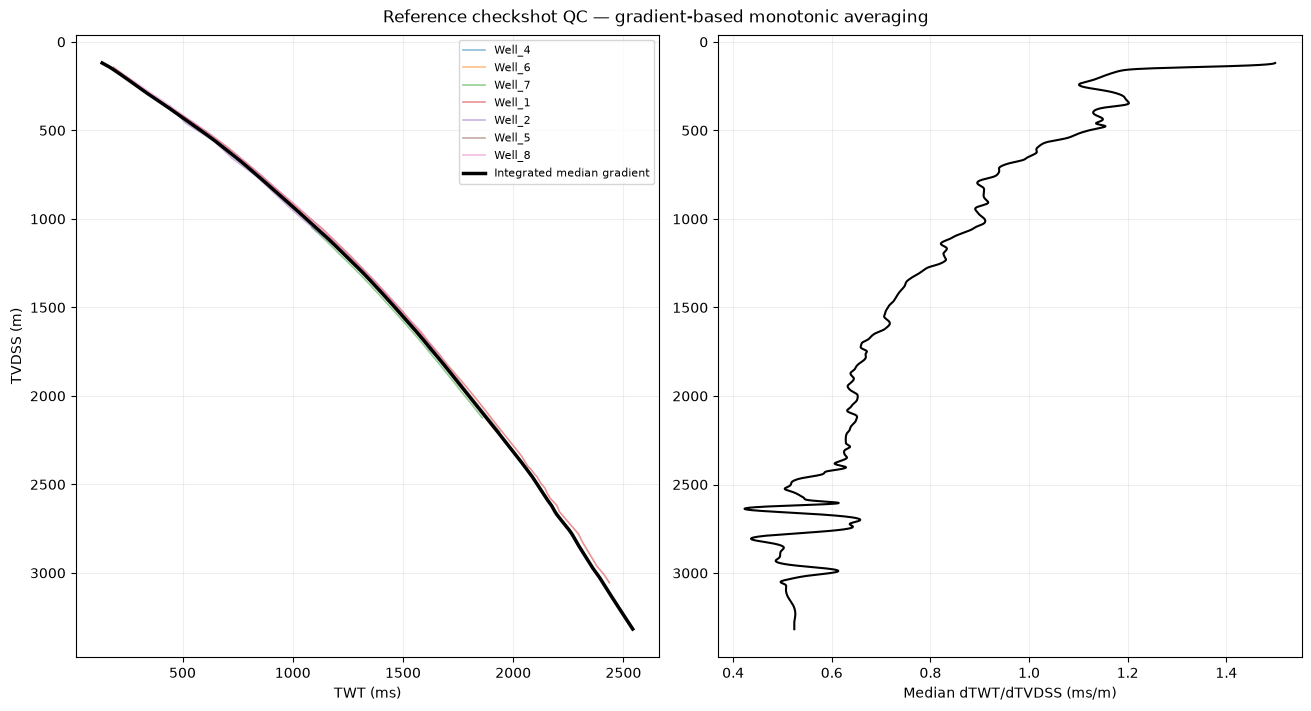

Reference TWT relationship: 3199 samples


In [86]:
# Cell 7 — Load checkshots and build average TWT(TVDSS) reference for Well 3
def read_checkshot(well):
    path=FILES[well]['checkshot']
    if path is None:return None
    shot=numeric_rows(path,2)
    if np.any(np.diff(shot[:,1])<=0):
        raise ValueError(f'{well}: checkshot TWT is not strictly increasing')
    return shot

for well in WELL_NAMES:
    WELLS[well]['checkshot']=read_checkshot(well)

# Reference checkshots from Phase 1 training wells + new wells with valid checkshots.
# Training well datum offsets are only used to understand their own surveys, not target well datum.
REF_CHECKSHOTS={}
for well in AVERAGE_TD_REFERENCE_WELLS:
    folder=ROOT/well
    if not folder.is_dir():
        warnings.warn(f'Reference {well}: missing folder {folder}');continue
    paths=sorted([p for p in folder.glob('*.txt') if 'checkshot' in p.stem.lower()])
    if len(paths)==1:REF_CHECKSHOTS[well]=numeric_rows(paths[0],2)
    else:warnings.warn(f'Reference {well}: expected one checkshot, found {len(paths)}')
if AVERAGE_TD_INCLUDE_TARGET_CHECKSHOTS:
    for well in WELL_NAMES:
        if well!='Well_3' and WELLS[well]['checkshot'] is not None:
            REF_CHECKSHOTS[well]=WELLS[well]['checkshot']
if not REF_CHECKSHOTS:raise RuntimeError('No checkshot reference surveys available for Well 3 fallback')
for well,shot in REF_CHECKSHOTS.items():
    print(well,'TVDSS:',shot[0,0],shot[-1,0],'m; TWT:',shot[0,1],shot[-1,1],'ms')

# Build the reference from the median POSITIVE local time-depth gradients,
# rather than the median absolute TWT (which can jump as well coverage changes).
# Anchor absolute TWT to a median of the original surveys at one common depth.
from scipy.interpolate import PchipInterpolator
all_min=min(s[0,0] for s in REF_CHECKSHOTS.values())
all_max=max(s[-1,0] for s in REF_CHECKSHOTS.values())
ref_z=np.arange(all_min,all_max+REFERENCE_STEP_M,REFERENCE_STEP_M)
slopes=[]
for well,shot in REF_CHECKSHOTS.items():
    if np.any(np.diff(shot[:,0])<=0) or np.any(np.diff(shot[:,1])<=0):
        raise ValueError(f'{well}: checkshot depths and times must strictly increase')
    fn=PchipInterpolator(shot[:,0],shot[:,1],extrapolate=False)
    gradient=fn.derivative()(ref_z)
    inside=(ref_z>=shot[0,0])&(ref_z<=shot[-1,0])
    gradient[~inside]=np.nan
    gradient[gradient<=0]=np.nan
    slopes.append(gradient)
slopes=np.vstack(slopes)
support=np.sum(np.isfinite(slopes),axis=0)
with warnings.catch_warnings():
    warnings.simplefilter('ignore',RuntimeWarning)
    median_gradient=np.nanmedian(slopes,axis=0)
median_gradient[support<REFERENCE_MIN_SUPPORT]=np.nan
good=np.isfinite(median_gradient)
if good.sum()<20:raise ValueError('Insufficient reference checkshot gradient support')
ref_z=ref_z[good][0]+np.arange(int(round((ref_z[good][-1]-ref_z[good][0])/REFERENCE_STEP_M))+1)*REFERENCE_STEP_M
# Internal missing support gaps are interpolated and reported explicitly.
good_z=np.arange(all_min,all_max+REFERENCE_STEP_M,REFERENCE_STEP_M)[good]
grad=np.interp(ref_z,good_z,median_gradient[good])
if np.any(np.diff(good_z)>REFERENCE_STEP_M*1.5):
    warnings.warn('Reference checkshots contain coverage gaps; gradients interpolated through gaps. Review QC.')
sigma=max(0.0,REFERENCE_DEPTH_SMOOTH_M/REFERENCE_STEP_M)
if sigma>0:grad=gaussian_filter1d(grad,sigma)
if np.any(~np.isfinite(grad)) or np.any(grad<=0):
    raise ValueError('Invalid median gradient; inspect checkshots and units')
# Choose the anchor where the largest number of reference surveys overlap.
anchor_idx=int(np.argmax(np.interp(ref_z,good_z,support[good])))
anchor_z=float(ref_z[anchor_idx])
anchor_values=[]
for shot in REF_CHECKSHOTS.values():
    if shot[0,0]<=anchor_z<=shot[-1,0]:
        anchor_values.append(float(np.interp(anchor_z,shot[:,0],shot[:,1])))
if not anchor_values:raise ValueError('No checkshots at reference anchor')
anchor_t=float(np.median(anchor_values))
ref_t=np.r_[0.0,np.cumsum((grad[1:]+grad[:-1])*0.5*np.diff(ref_z))]
ref_t+=anchor_t-np.interp(anchor_z,ref_z,ref_t)
assert np.all(np.diff(ref_t)>0),'Reference TWT not strictly monotonic'
print(f'Reference anchor: {anchor_z:.1f} m TVDSS, {anchor_t:.1f} ms, '
      f'{len(anchor_values)} checkshots; gradient {grad.min():.3f}–{grad.max():.3f} ms/m')
fig,ax=plt.subplots(1,2,figsize=(13,7),constrained_layout=True)
for well,shot in REF_CHECKSHOTS.items():
    ax[0].plot(shot[:,1],shot[:,0],alpha=.5,lw=1.2,label=well)
ax[0].plot(ref_t,ref_z,'k',lw=2.5,label='Integrated median gradient')
ax[0].invert_yaxis();ax[0].set_xlabel('TWT (ms)');ax[0].set_ylabel('TVDSS (m)')
ax[0].legend(fontsize=8);ax[0].grid(alpha=.2)
ax[1].plot(grad,ref_z,color='black',lw=1.5)
ax[1].invert_yaxis();ax[1].set_xlabel('Median dTWT/dTVDSS (ms/m)')
ax[1].grid(alpha=.2)
fig.suptitle('Reference checkshot QC — gradient-based monotonic averaging')
fig.savefig(OUTPUT_ROOT/'Well3_Average_Checkshot_Reference_QC.png',dpi=180,bbox_inches='tight')
plt.show();plt.close(fig)

def reference_twt(z):
    z=np.asarray(z,float)
    # Controlled linear gradient extrapolation, never unlimited.
    lo,hi=ref_z[0],ref_z[-1]
    if np.any(np.isfinite(z)&((z<lo-REFERENCE_EXTRAPOLATION_MAX_M)|
                              (z>hi+REFERENCE_EXTRAPOLATION_MAX_M))):
        warnings.warn('Some depths extend beyond allowed reference extrapolation; TWT will be NaN')
    v=np.interp(z,ref_z,ref_t)
    slope_lo=(ref_t[5]-ref_t[0])/(ref_z[5]-ref_z[0])
    slope_hi=(ref_t[-1]-ref_t[-6])/(ref_z[-1]-ref_z[-6])
    v=np.where(z<lo,ref_t[0]+(z-lo)*slope_lo,v)
    v=np.where(z>hi,ref_t[-1]+(z-hi)*slope_hi,v)
    v=np.where((z<lo-REFERENCE_EXTRAPOLATION_MAX_M)|
               (z>hi+REFERENCE_EXTRAPOLATION_MAX_M),np.nan,v)
    return v

pd.DataFrame({'TVDSS_m':ref_z,'Mean_Checkshot_TWT_ms':ref_t}).to_csv(
    OUTPUT_ROOT/'Well3_Average_Checkshot_TD_Reference.csv',index=False)
print('Reference TWT relationship:',len(ref_z),'samples')

Well_1 TWT coverage 99.7% TWT range 386.3734908136483 2435.9310826206183
Well_2 TWT coverage 97.1% TWT range 441.5192288 2538.3865528049187
Well 3: DTC_P, us/ft; DTC supported 14,675/14,931 samples; TWT 1143.5–2539.3 ms; anchor 2196.8 m TVDSS


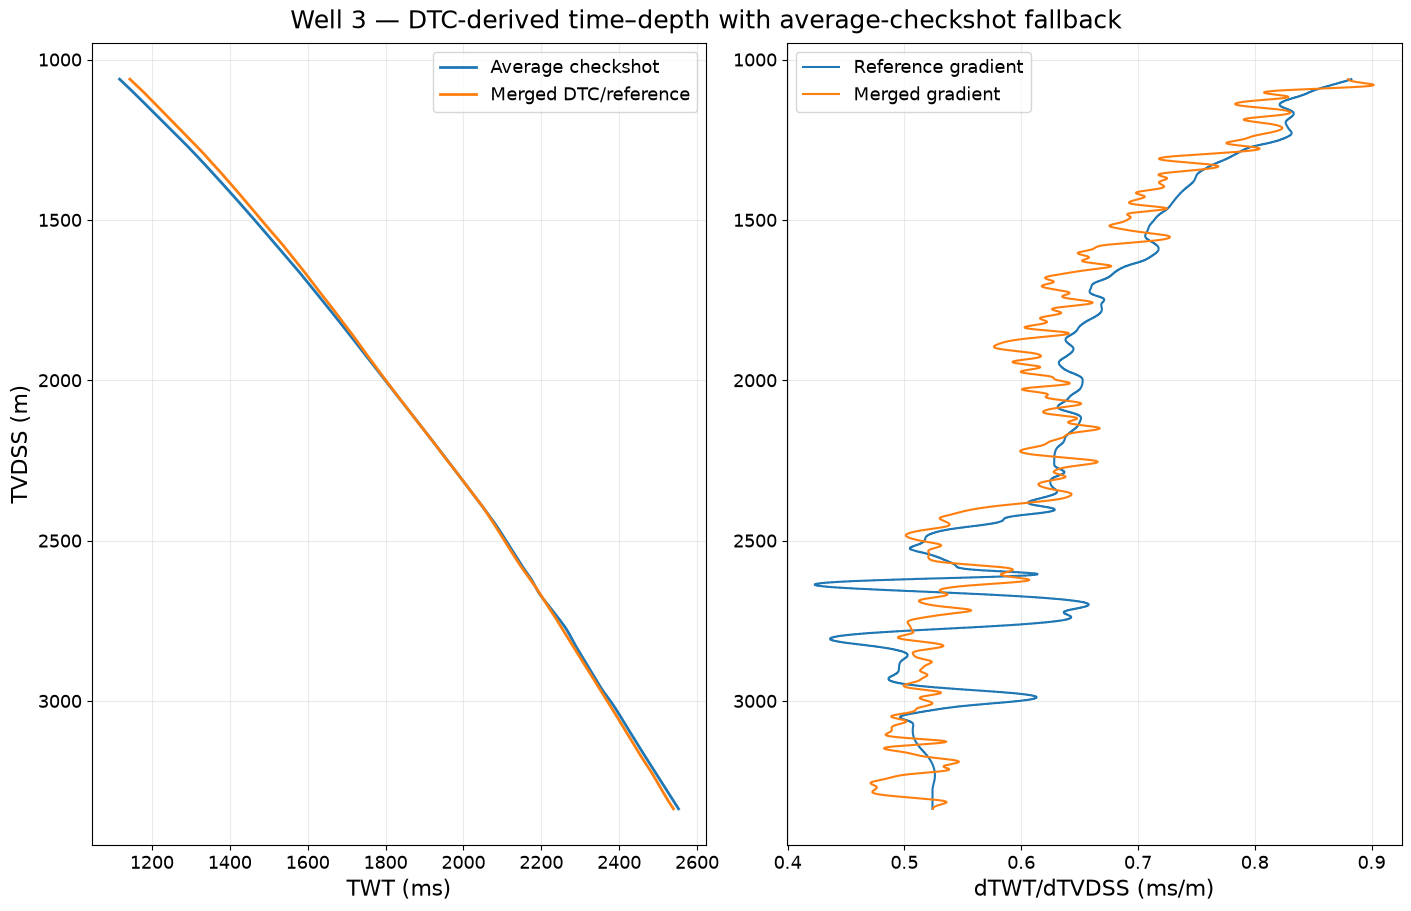

Well_3 TWT coverage 100.0% TWT range 1143.4725812839743 2539.3244208776932
Well_5 TWT coverage 93.1% TWT range 1163.2433759770308 1932.5830873614204
Well_8 TWT coverage 98.6% TWT range 1018.5598400000001 1768.0994224
Well_3: exported 457 estimated checkshot points
  LAS: /home/apgce_team_08/link-to-apgce_team_08/Well_To_Predict_Phase4_Output/Well_3/Well_3_Established_Checkshot.las
  TXT: /home/apgce_team_08/link-to-apgce_team_08/Well_To_Predict_Phase4_Output/Well_3/Well_3_Established_Checkshot.txt
  TVDSS 1061.11–3336.44 m; TWT 1143.47–2539.32 ms


In [87]:
# Cell 8 — Well 3 DTC integration + reference fallback + smoothed transition
# Sonic slowness is integrated as two-way time gradient in ms/m of TVDSS.
# For deviated wells DTC measures along borehole MD; Well 3 should be vertical or
# the integration must be converted appropriately. A vertical assumption is flagged.
def dtc_to_usft(well,values,unit):
    u=re.sub(r'\s+','',str(unit).lower()).replace('µ','u').replace('μ','u')
    if u in ('us/ft','us/f','usec/ft','us/feet','us/foot'):return values
    if u in ('us/m','usec/m'):return values/3.280839895
    if u in ('s/m',):return values*1e6/3.280839895
    raise ValueError(f'{well}: DTC unit {unit!r} unrecognized. Set DTC_UNIT_OVERRIDE after verification.')

def build_well3_dtc_twt(well='Well_3'):
    frame=WELLS[well]['raw']
    names=[c for c in DTC_CURVE_CANDIDATES if c in frame.columns]
    if not names:raise ValueError('Well 3 has no DTC candidate. Add a verified CURVE_ALIASES mapping.')
    curve=next((c for c in names if frame[c].notna().sum()>=DTC_MIN_VALID_SAMPLES),None)
    if curve is None:raise ValueError('Well 3 DTC coverage too small; inspect candidate logs.')
    unit=DTC_UNIT_OVERRIDE.get(well,WELLS[well]['units'].get(curve,''))
    z=frame.TVDSS_m.to_numpy(float)
    md=frame.MDKB_m.to_numpy(float)
    dtc=np.array(dtc_to_usft(well,frame[curve].to_numpy(dtype=np.float64,copy=True),unit),copy=True)
    dtc[(dtc<DTC_MIN_USFT)|(dtc>DTC_MAX_USFT)]=np.nan
    if not WELLS[well]['vertical']:
        warnings.warn('Well 3 is deviated: DTC is along MD; integration uses MD-based sonic increments. '
                      'Review sonic time-depth methodology before accepting results.')
    if np.any(np.diff(z[np.isfinite(z)])<=0):
        raise ValueError('Well 3 TVDSS must increase monotonically; inspect deviation')
    ref=reference_twt(z)
    ref_gradient=np.gradient(ref,z)
    # For vertical wells, 2*us/ft*3.28084/1000 = ms/m.
    dtc_gradient=2.0*dtc*3.280839895/1000.0
    if not WELLS[well]['vertical']:
        dz_dmd=np.gradient(z,md)
        dtc_gradient=dtc_gradient/np.where(dz_dmd>0.05,dz_dmd,np.nan)
    # Keep DTC only in supported intervals; no bridging large gaps.
    valid=np.isfinite(dtc_gradient)&np.isfinite(z)
    supported=np.zeros(len(z),bool)
    ix=np.flatnonzero(valid)
    if len(ix)<DTC_MIN_VALID_SAMPLES:raise ValueError('Too few valid Well 3 DTC samples')
    for a,b in zip(ix[:-1],ix[1:]):
        if z[b]-z[a]<=DTC_MAX_INTERPOLATION_GAP_M:supported[a:b+1]=True
    supported[ix]=True
    if np.any(~np.isfinite(ref_gradient)):
        raise ValueError('Reference TD does not cover Well 3 depth. Extend reference support or adjust extrapolation explicitly.')
    sonic_grad=np.interp(z,z[valid],dtc_gradient[valid])
    combined=np.where(supported,sonic_grad,ref_gradient)
    # Smooth the GRADIENT, not TWT, to avoid abrupt slopes at merged boundaries.
    median_step=float(np.median(np.diff(z)))
    sigma=max(0.0,DTC_TRANSITION_SMOOTH_M/max(median_step,1e-6))
    if sigma>0:combined=gaussian_filter1d(combined,sigma=sigma)
    combined=np.maximum(combined,0.05) # physically positive TWT gradient
    cumulative=np.r_[0,np.cumsum(0.5*(combined[1:]+combined[:-1])*np.diff(z))]
    anchor=(float(DTC_ANCHOR_TVDSS_M) if DTC_ANCHOR_TVDSS_M is not None
            else float(np.nanmedian(z[supported])))
    anchor_ref=float(reference_twt([anchor])[0])
    twt=cumulative+anchor_ref-np.interp(anchor,z,cumulative)
    if np.any(np.diff(twt)<=0):raise RuntimeError('Nonmonotonic Well 3 time-depth relation')
    frame['TWT_ms']=twt
    frame['TD_SOURCE']=np.where(supported,'DTC','AVERAGE_CHECKSHOT')
    frame['DTC_TWT_GRADIENT_ms_per_m']=dtc_gradient
    frame['MERGED_TWT_GRADIENT_ms_per_m']=combined
    WELLS[well]['raw']=frame
    print(f'Well 3: {curve}, {unit}; DTC supported {supported.sum():,}/{len(z):,} samples; '
          f'TWT {twt[0]:.1f}–{twt[-1]:.1f} ms; anchor {anchor:.1f} m TVDSS')
    qc=frame[['MDKB_m','TVDSS_m','TWT_ms','TD_SOURCE',
              'DTC_TWT_GRADIENT_ms_per_m','MERGED_TWT_GRADIENT_ms_per_m']]
    qc.to_csv(OUTPUT_ROOT/'Well_3_DTC_Merged_TimeDepth_QC.csv',index=False)
    fig,axs=plt.subplots(1,2,figsize=(14,9),constrained_layout=True)
    axs[0].plot(ref,z,label='Average checkshot',lw=2)
    axs[0].plot(twt,z,label='Merged DTC/reference',lw=2)
    axs[0].invert_yaxis();axs[0].set_xlabel('TWT (ms)',fontsize=16)
    axs[0].set_ylabel('TVDSS (m)',fontsize=16);axs[0].legend(fontsize=13);axs[0].grid(alpha=.25)
    axs[1].plot(ref_gradient,z,label='Reference gradient',lw=1.5)
    axs[1].plot(combined,z,label='Merged gradient',lw=1.5)
    axs[1].invert_yaxis();axs[1].set_xlabel('dTWT/dTVDSS (ms/m)',fontsize=16)
    axs[1].legend(fontsize=13);axs[1].grid(alpha=.25)
    for ax in axs:ax.tick_params(labelsize=13)
    fig.suptitle('Well 3 — DTC-derived time–depth with average-checkshot fallback',fontsize=18)
    fig.savefig(OUTPUT_ROOT/'Well_3_DTC_Merged_TD_QC.png',dpi=180,bbox_inches='tight')
    plt.show();plt.close(fig)

# Export the established Well 3 time-depth relationship as LAS 2.0 and as
# the two-column TXT format expected by read_checkshot()/numeric_rows().
# The relationship is estimated from DTC + other-well checkshot reference,
# NOT an independently measured checkshot survey.
EXPORT_WELL3_ESTIMATED_CHECKSHOT = True
WELL3_CHECKSHOT_EXPORT_STEP_M = 5.0  # regular TVDSS sampling, plus endpoints
WELL3_CHECKSHOT_EXPORT_PREFIX = 'Well_3_Established_Checkshot'

def export_well3_estimated_checkshot(well='Well_3'):
    if not EXPORT_WELL3_ESTIMATED_CHECKSHOT:
        return
    frame = WELLS[well]['raw']
    z = pd.to_numeric(frame['TVDSS_m'], errors='coerce').to_numpy(dtype=float)
    t = pd.to_numeric(frame['TWT_ms'], errors='coerce').to_numpy(dtype=float)
    good = np.isfinite(z) & np.isfinite(t)
    z, t = z[good], t[good]
    if len(z) < 2:
        raise ValueError(f'{well}: insufficient finite time-depth pairs to export')
    order = np.argsort(z)
    z, t = z[order], t[order]
    z, unique_ix = np.unique(z, return_index=True)
    t = t[unique_ix]
    if np.any(np.diff(z) <= 0) or np.any(np.diff(t) <= 0):
        raise ValueError(f'{well}: checkshot export requires strictly increasing TVDSS and TWT')
    step = float(WELL3_CHECKSHOT_EXPORT_STEP_M)
    if not np.isfinite(step) or step <= 0:
        raise ValueError('WELL3_CHECKSHOT_EXPORT_STEP_M must be positive')
    # Regular depth nodes plus exact log endpoints, with no extrapolation.
    nodes = np.arange(np.ceil(z[0]/step)*step, z[-1], step)
    nodes = np.unique(np.r_[z[0], nodes, z[-1]])
    times = np.interp(nodes, z, t)
    if np.any(np.diff(times) <= 0):
        raise ValueError(f'{well}: resampled checkshot TWT is not strictly increasing')

    output_folder = OUTPUT_ROOT / well
    output_folder.mkdir(parents=True, exist_ok=True)
    las_path = output_folder / (WELL3_CHECKSHOT_EXPORT_PREFIX + '.las')
    txt_path = output_folder / (WELL3_CHECKSHOT_EXPORT_PREFIX + '.txt')

    # LAS 2.0 with depth as index, and TWT as a curve (not a time-indexed LAS).
    import lasio
    las = lasio.LASFile()
    las.version.VERS.value = 2.0
    las.version.WRAP.value = 'NO'
    las.well.WELL.value = well
    las.well.STRT.value = float(nodes[0])
    las.well.STRT.unit = 'M'
    las.well.STOP.value = float(nodes[-1])
    las.well.STOP.unit = 'M'
    las.well.STEP.value = 0.0  # irregular first/last spacing; sampled nodes are explicit
    las.well.STEP.unit = 'M'
    las.well.NULL.value = -999.25
    las.append_curve('TVDSS', nodes, unit='M', descr='True vertical depth subsea, positive down')
    las.append_curve('TWT', times, unit='MS', descr='Estimated two-way travel time')
    las.other = ('ESTIMATED CHECKSHOT: NOT MEASURED. Well 3 DTC-derived '
                 'time-depth with average-checkshot fallback; see Phase 4 QC.')
    las.write(str(las_path), version=2.0, wrap=False)

    # Match original numeric checkshot input: TVDSS (m) then TWT (ms), no header.
    np.savetxt(txt_path, np.column_stack((nodes,times)),
               fmt='%.6f', delimiter='\t')

    # Read back the exported LAS/TXT and verify numeric agreement.
    check_las = lasio.read(str(las_path))
    las_depth = np.asarray(check_las.index, dtype=float)
    las_twt = np.asarray(check_las['TWT'], dtype=float)
    check_txt = numeric_rows(txt_path, 2)
    if not (np.allclose(las_depth,nodes,atol=1e-4,rtol=0) and
            np.allclose(las_twt,times,atol=1e-3,rtol=0) and
            np.allclose(check_txt[:,0],nodes,atol=1e-4,rtol=0) and
            np.allclose(check_txt[:,1],times,atol=1e-3,rtol=0)):
        raise RuntimeError('Exported LAS/TXT checkshot read-back verification failed')
    print(f'{well}: exported {len(nodes):,} estimated checkshot points')
    print('  LAS:',las_path)
    print('  TXT:',txt_path)
    print(f'  TVDSS {nodes[0]:.2f}–{nodes[-1]:.2f} m; TWT {times[0]:.2f}–{times[-1]:.2f} ms')
    return las_path, txt_path

for well in WELL_NAMES:
    if well=='Well_3' and WELLS[well]['checkshot'] is None:
        build_well3_dtc_twt(well)
    else:
        shot=WELLS[well]['checkshot']
        if shot is None:raise ValueError(f'{well}: missing checkshot')
        frame=WELLS[well]['raw']
        frame['TWT_ms']=np.interp(frame.TVDSS_m.to_numpy(float),shot[:,0],shot[:,1],
                                  left=np.nan,right=np.nan)
        frame['TD_SOURCE']='CHECKSHOT'
        WELLS[well]['raw']=frame
    markers=WELLS[well]['markers'].copy()
    if len(markers):
        shot=WELLS[well]['checkshot']
        if shot is not None:
            markers['TWT_ms']=np.interp(markers.Marker_TVDSS_m.to_numpy(float),
                                        shot[:,0],shot[:,1],left=np.nan,right=np.nan)
        else:
            markers['TWT_ms']=np.interp(markers.Marker_TVDSS_m.to_numpy(float),
                                        WELLS[well]['raw'].TVDSS_m.to_numpy(float),
                                        WELLS[well]['raw'].TWT_ms.to_numpy(float),
                                        left=np.nan,right=np.nan)
    else:markers['TWT_ms']=pd.Series(dtype=float)
    WELLS[well]['markers']=markers
    frame=WELLS[well]['raw']
    print(well,'TWT coverage',f'{frame.TWT_ms.notna().mean():.1%}',
          'TWT range',frame.TWT_ms.min(),frame.TWT_ms.max())

# Export only after all well time-depth relationships have been established.
if WELLS['Well_3']['checkshot'] is None:
    WELL3_CHECKSHOT_EXPORT_FILES = export_well3_estimated_checkshot('Well_3')
else:
    print('Well 3 has a measured checkshot; estimated checkshot export skipped.')


In [88]:
# Cell 9 — Build exactly the Phase 1 feature matrix (including missing Well 3 markers)
JOINED={}
for well,d in WELLS.items():
    frame=d['raw'].copy().reset_index(drop=True)
    for c in INPUTS:
        frame['RAW_'+c]=frame[c] if c in frame else np.nan
    if not frame[EXPECTED_INPUTS].notna().any(axis=1).any():
        raise ValueError(f'{well}: no usable measured inputs matching Phase 1 feature vocabulary')
    JOINED[well]=frame
print('Input availability:')
display(pd.DataFrame({w:{c:int(f['RAW_'+c].notna().sum()) for c in INPUTS}
                      for w,f in JOINED.items()}).T)

Input availability:


,CALI_P,DENS_P,GR_P,NEUT_P,NPHIHC,PEF_P,RHOBHC,RT_P
Well_1,13759,13740,17957,9458,9370,0,9370,17938
Well_2,19972,19702,19609,19698,14828,19972,14832,19811
Well_3,14783,14514,14432,14475,13892,14783,13892,14724
Well_5,7673,7422,7673,7422,7422,7422,7422,7422
Well_8,6710,6423,6547,6423,6352,0,6352,6540


In [100]:
# Cell 9A — Export similar marker names across ALL eight wells (1–8)
# Review only: no automatic merges or changes to model training vocabulary.
from difflib import SequenceMatcher
from itertools import combinations

MARKER_SIMILARITY_THRESHOLD = 0.78
MARKER_REMOVE_TOP_SUFFIX_FOR_SUGGESTIONS = True
MARKER_ALIAS_OVERRIDES = {}  # e.g. {'I-35.0 TOP': 'I-35.0'} after geological QC
INCLUDE_TRAINED_VOCABULARY_AS_REFERENCE = True
ALL_WELLS_FOR_MARKER_QC = [f'Well_{i}' for i in range(1,9)]
if not 0 <= MARKER_SIMILARITY_THRESHOLD <= 1:
    raise ValueError('MARKER_SIMILARITY_THRESHOLD must be between 0 and 1')

def clean_marker_label(s):
    return re.sub(r'\s+', ' ', str(s).strip().upper())

def marker_compare_key(s):
    s = clean_marker_label(s)
    if MARKER_REMOVE_TOP_SUFFIX_FOR_SUGGESTIONS:
        s = re.sub(r'(?:[\s_\-]+)?TOP$', '', s).strip(' _-')
    return re.sub(r'[^A-Z0-9]+', '', s)

# Explicitly override if the marker file is outside the standard directories.
TRAINING_MARKER_FILE_OVERRIDES = {
    'Well_4': Path('/home/apgce_team_08/link-to-apgce_team_08/Well_4/Well-4_Markers.txt'),
    'Well_6': Path('/home/apgce_team_08/link-to-apgce_team_08/Well_6/Well-6_Markers.txt'),
    'Well_7': Path('/home/apgce_team_08/link-to-apgce_team_08/Well_7/Well-7_Markers.txt'),
}
# Search the original project tree, not just ROOT/Well_4. Do not search
# Phase 4 outputs, where generated CSVs can be mistaken for source markers.
TRAINING_MARKER_SEARCH_ROOTS = [ROOT]
REQUIRE_WELL4_MARKERS = True  # fail rather than silently export an empty Well_4

def find_training_marker_file(well):
    number = int(re.search(r'\d+', well).group())
    well_token = re.compile(rf'(?i)(?<![a-z0-9])well[_\s-]*0*{number}(?![0-9])')
    candidates = []
    for search_root in TRAINING_MARKER_SEARCH_ROOTS:
        search_root = Path(search_root)
        if not search_root.is_dir():
            continue
        for path in search_root.rglob('*'):
            if not path.is_file() or path.suffix.lower() not in ('.txt','.tsv','.csv'):
                continue
            if not any(k in path.stem.lower() for k in ('marker','tops')):
                continue
            if 'Well_To_Predict_Phase4_Output' in path.parts:
                continue
            if well_token.search(path.stem) or any(well_token.search(part) for part in path.parts):
                candidates.append(path)
    candidates = sorted(set(candidates))
    # Prefer source file explicitly naming the well and markers.
    named = [path for path in candidates if well_token.search(path.stem)]
    if len(named) == 1:
        return named[0]
    if len(candidates) == 1:
        return candidates[0]
    if candidates:
        print(f'{well}: multiple candidate marker files found:')
        for path in candidates: print('   ',path)
        print('Set TRAINING_MARKER_FILE_OVERRIDES to select the correct file.')
    else:
        print(f'{well}: no source marker file found under {TRAINING_MARKER_SEARCH_ROOTS}')
    return None

marker_rows = []
source_status = []
for well in ALL_WELLS_FOR_MARKER_QC:
    if well == 'Well_3':
        # Geological constraint: no marker picks exist for Well 3.
        # Record this explicitly, even if an erroneous file or stale WELLS
        # dataframe contains marker rows.
        stale_count = len(WELLS.get(well, {}).get('markers', []))
        if stale_count:
            print(f'WARNING: ignored {stale_count} unexpected Well 3 marker rows')
        source_status.append({'Well':well,'Status':'NO_MARKERS_CONFIRMED',
                              'Marker_file':'','Rows':0})
        continue
    if well in WELLS:
        marker_df = WELLS[well].get('markers')
        source_file = FILES.get(well,{}).get('markers')
        status = 'LOADED' if marker_df is not None and len(marker_df) else 'NO_MARKERS'
    else:
        path = TRAINING_MARKER_FILE_OVERRIDES.get(well)
        if path is None:
            path = find_training_marker_file(well)
        if path is not None and Path(path).is_file():
            marker_df = read_markers(path)
            status = 'LOADED' if len(marker_df) else 'NO_PARSEABLE_MARKERS'
        else:
            marker_df = None
            status = 'FILE_NOT_FOUND'
        source_file = path
    source_status.append({'Well':well,'Status':status,
                          'Marker_file':str(source_file) if source_file else '',
                          'Rows':0 if marker_df is None else len(marker_df)})
    if marker_df is None or 'Marker' not in marker_df:
        continue
    for _, m in marker_df.iterrows():
        name = clean_marker_label(m['Marker'])
        if not name or name in ('NAN','NONE'):
            continue
        marker_rows.append({
            'Well':well,'Marker':name,
            'MDKB_m':pd.to_numeric(m.get('MDKB_m',np.nan),errors='coerce'),
            'TVDSS_m':pd.to_numeric(m.get('Marker_TVDSS_m',np.nan),errors='coerce'),
            'Marker_file':str(source_file) if source_file else '',
            'Source':'WELL_MARKER'
        })
if INCLUDE_TRAINED_VOCABULARY_AS_REFERENCE:
    for name in MARKER_VOCABULARY:
        name=clean_marker_label(name)
        if name:
            marker_rows.append({'Well':'TRAINING_VOCABULARY','Marker':name,
                                'MDKB_m':np.nan,'TVDSS_m':np.nan,
                                'Marker_file':'Phase 1 saved manifest',
                                'Source':'TRAINED_VOCABULARY'})

# Hard-stop safeguard: no Well 3 marker may enter any export.
assert not any(r['Well']=='Well_3' for r in marker_rows), \
    'Unexpected Well 3 marker entered the export inventory'
status_df=pd.DataFrame(source_status)
status_df.to_csv(OUTPUT_ROOT/'Phase4_All_Wells_Marker_Source_Status.csv',index=False)
display(status_df)
well4_status = next((r for r in source_status if r['Well']=='Well_4'), None)
if REQUIRE_WELL4_MARKERS and (well4_status is None or well4_status['Rows']==0):
    raise FileNotFoundError(
        'Well_4 marker source was not loaded. Inspect search diagnostics and set '
        'TRAINING_MARKER_FILE_OVERRIDES[\"Well_4\"] to the original marker TXT/TSV/CSV file. '
        'No incomplete marker-comparison CSVs have been written by this run.'
    )
marker_occurrences = pd.DataFrame(marker_rows,columns=[
    'Well','Marker','MDKB_m','TVDSS_m','Marker_file','Source'])
assert marker_occurrences.loc[marker_occurrences['Well']=='Well_3'].empty
marker_occurrences.to_csv(OUTPUT_ROOT/'Phase4_All_Wells_Marker_Inventory.csv',index=False)
print('Marker occurrences:',len(marker_occurrences))

# Pairwise comparisons: only compare names from different wells, or well vs
# training vocabulary. Same-well spelling variants can also be useful QC.
unique = (marker_occurrences[['Well','Marker']].drop_duplicates()
          .to_dict('records'))
pair_rows=[]
for a,b in combinations(unique,2):
    name_a,name_b=a['Marker'],b['Marker']
    if name_a==name_b:
        score=1.0
        kind='EXACT_MATCH'
    else:
        ka,kb=marker_compare_key(name_a),marker_compare_key(name_b)
        score=SequenceMatcher(None,ka,kb).ratio() if ka and kb else 0.0
        kind=('TOP_SUFFIX_VARIANT' if ka==kb else
              'VERY_SIMILAR' if score>=0.92 else 'SIMILAR')
    if score < MARKER_SIMILARITY_THRESHOLD:
        continue
    # Keep exact matches between different wells; avoid duplicate same-well pairs.
    if a['Well']==b['Well']:
        continue
    pair_rows.append({
        'Well_A':a['Well'],'Marker_A':name_a,
        'Well_B':b['Well'],'Marker_B':name_b,
        'Similarity':round(score,3),'Flag':kind,
        'Review_Status':'REVIEW_ONLY_NOT_AUTO_MERGED'
    })
PAIR_COLS=['Well_A','Marker_A','Well_B','Marker_B','Similarity','Flag','Review_Status']
MARKER_SIMILARITY_REPORT=pd.DataFrame(pair_rows,columns=PAIR_COLS)
if not MARKER_SIMILARITY_REPORT.empty:
    MARKER_SIMILARITY_REPORT=MARKER_SIMILARITY_REPORT.sort_values(
        ['Similarity','Well_A','Well_B'],ascending=[False,True,True])
pair_path=OUTPUT_ROOT/'Phase4_All_Wells_Similar_Markers_Pairs.csv'
MARKER_SIMILARITY_REPORT.to_csv(pair_path,index=False)

# A second, presentation-friendly CSV: one row per normalized marker key,
# with the matched names in Well_1 ... Well_8 columns.
# This grouping is a *suggestion*, not a validated horizon correlation.
well_names=ALL_WELLS_FOR_MARKER_QC
well_only=marker_occurrences[marker_occurrences['Well'].isin(well_names)]
unique_names=sorted(well_only['Marker'].unique())
# Use exact normalized keys as grouping anchors, then attach fuzzy variants
# to the closest anchor. This avoids transitive chaining of unrelated horizons.
keys={name:marker_compare_key(name) for name in unique_names}
anchors={}
for name in unique_names:
    k=keys[name]
    anchors.setdefault(k,[]).append(name)
group_rows=[]
for key,names in sorted(anchors.items()):
    row={'Candidate_Marker_Group':key,
         'Distinct_Names':'; '.join(names),
         'Review_Status':'UNVERIFIED_SIMILARITY_GROUP'}
    for well in well_names:
        present=sorted(set(well_only.loc[
            (well_only.Well==well)&well_only.Marker.isin(names),'Marker']))
        row[well]='; '.join(present)
    row['Wells_Present']=sum(bool(row[w]) for w in well_names)
    group_rows.append(row)
GROUP_COLS=['Candidate_Marker_Group','Distinct_Names',*well_names,
            'Wells_Present','Review_Status']
MARKER_GROUP_REPORT=pd.DataFrame(group_rows,columns=GROUP_COLS)
if not MARKER_GROUP_REPORT.empty:
    assert MARKER_GROUP_REPORT['Well_3'].fillna('').eq('').all(), \
        'Well 3 must have zero markers in the by-well CSV'
group_path=OUTPUT_ROOT/'Phase4_All_Wells_Similar_Markers_By_Well.csv'
MARKER_GROUP_REPORT.to_csv(group_path,index=False)
assert MARKER_GROUP_REPORT['Well_3'].fillna('').eq('').all(), \
    'Well 3 column must remain blank'
assert not MARKER_SIMILARITY_REPORT[['Well_A','Well_B']].eq('Well_3').any().any(), \
    'Well 3 must not appear in marker similarity pairs'
print('QC PASS: Well_3 has no marker entries in inventory, pairwise comparisons, or grouped CSV')

print('Saved pairwise similar/exact markers:',pair_path,
      f'({len(MARKER_SIMILARITY_REPORT)} comparisons)')
print('Saved marker names by well:',group_path,
      f'({len(MARKER_GROUP_REPORT)} normalized-name groups)')
print('Saved complete inventory and source-status CSVs.')
display(MARKER_SIMILARITY_REPORT.head(80))
display(MARKER_GROUP_REPORT.head(80))

# Preserve Phase 1 marker vocabulary exactly; apply only manually approved aliases.
trained_names={clean_marker_label(s) for s in MARKER_VOCABULARY}
for alias,canonical in MARKER_ALIAS_OVERRIDES.items():
    if clean_marker_label(canonical) not in trained_names:
        raise ValueError(f'Approved alias {alias!r} maps to {canonical!r}, absent from trained vocabulary')
    APPROVED_MARKER_MAPPING[clean_marker_label(alias)] = clean_marker_label(canonical)

Marker parser Well-4_Markers.txt: 22 rows, 0 unparsed lines
Marker parser Well-6_Markers.txt: 15 rows, 0 unparsed lines
Marker parser Well-7_Markers.txt: 7 rows, 0 unparsed lines


,Well,Status,Marker_file,Rows
0,Well_1,LOADED,/home/apgce_team_08/link-to-apgce_team_08/Well...,5
1,Well_2,LOADED,/home/apgce_team_08/link-to-apgce_team_08/Well...,23
2,Well_3,NO_MARKERS_CONFIRMED,,0
3,Well_4,LOADED,/home/apgce_team_08/link-to-apgce_team_08/Well...,22
4,Well_5,LOADED,/home/apgce_team_08/link-to-apgce_team_08/Well...,16
5,Well_6,LOADED,/home/apgce_team_08/link-to-apgce_team_08/Well...,15
6,Well_7,LOADED,/home/apgce_team_08/link-to-apgce_team_08/Well...,7
7,Well_8,LOADED,/home/apgce_team_08/link-to-apgce_team_08/Well...,11


Marker occurrences: 129
QC PASS: Well_3 has no marker entries in inventory, pairwise comparisons, or grouped CSV
Saved pairwise similar/exact markers: /home/apgce_team_08/link-to-apgce_team_08/Well_To_Predict_Phase4_Output/Phase4_All_Wells_Similar_Markers_Pairs.csv (254 comparisons)
Saved marker names by well: /home/apgce_team_08/link-to-apgce_team_08/Well_To_Predict_Phase4_Output/Phase4_All_Wells_Similar_Markers_By_Well.csv (54 normalized-name groups)
Saved complete inventory and source-status CSVs.


,Well_A,Marker_A,Well_B,Marker_B,Similarity,Flag,Review_Status
11,Well_1,TOP_GROUP_I,TRAINING_VOCABULARY,TOP_GROUP_I,1.0,EXACT_MATCH,REVIEW_ONLY_NOT_AUTO_MERGED
24,Well_1,TOP_GROUP_J,TRAINING_VOCABULARY,TOP_GROUP_J,1.0,EXACT_MATCH,REVIEW_ONLY_NOT_AUTO_MERGED
37,Well_1,TOP_GROUP_K,TRAINING_VOCABULARY,TOP_GROUP_K,1.0,EXACT_MATCH,REVIEW_ONLY_NOT_AUTO_MERGED
1,Well_1,TOP_GROUP_I,Well_2,TOP_GROUP_I,1.0,EXACT_MATCH,REVIEW_ONLY_NOT_AUTO_MERGED
28,Well_1,TOP_GROUP_K,Well_2,TOP_GROUP_K,1.0,EXACT_MATCH,REVIEW_ONLY_NOT_AUTO_MERGED
...,...,...,...,...,...,...,...
153,Well_4,I-120,Well_6,I-120,1.0,EXACT_MATCH,REVIEW_ONLY_NOT_AUTO_MERGED
160,Well_4,J-10,Well_6,J-10,1.0,EXACT_MATCH,REVIEW_ONLY_NOT_AUTO_MERGED
163,Well_4,J-15,Well_6,J-15,1.0,EXACT_MATCH,REVIEW_ONLY_NOT_AUTO_MERGED
166,Well_4,J-20,Well_6,J-20,1.0,EXACT_MATCH,REVIEW_ONLY_NOT_AUTO_MERGED


,Candidate_Marker_Group,Distinct_Names,Well_1,Well_2,Well_3,Well_4,Well_5,Well_6,Well_7,Well_8,Wells_Present,Review_Status
0,BASALBUNCONFORMITY,BASAL_B_UNCONFORMITY,,BASAL_B_UNCONFORMITY,,,,,,,1,UNVERIFIED_SIMILARITY_GROUP
1,GROUPH,GROUP_H,,,,,,,GROUP_H,,1,UNVERIFIED_SIMILARITY_GROUP
2,GROUPI,GROUP_I,,,,,,,GROUP_I,,1,UNVERIFIED_SIMILARITY_GROUP
3,I1,I-1,,,,,I-1,I-1,,,2,UNVERIFIED_SIMILARITY_GROUP
4,I100,I-100,,,,I-100,I-100,I-100,I-100,I-100,5,UNVERIFIED_SIMILARITY_GROUP
5,I110COAL,I-110_COAL,,I-110_COAL,,,,,,,1,UNVERIFIED_SIMILARITY_GROUP
6,I115,I-115,,,,I-115,I-115,I-115,,,3,UNVERIFIED_SIMILARITY_GROUP
7,I118,I-118,,,,,I-118,I-118,,,2,UNVERIFIED_SIMILARITY_GROUP
8,I120,I-120,,,,I-120,I-120,I-120,,,3,UNVERIFIED_SIMILARITY_GROUP
9,I150L,I-15.0L,,,,,,,,I-15.0L,1,UNVERIFIED_SIMILARITY_GROUP


In [101]:
# Cell 10 — Exact training-time marker encoding, using saved vocabulary
def normalize_marker_name(name):
    normalized=re.sub(r"\s+", " ", str(name).strip().upper())
    return APPROVED_MARKER_MAPPING.get(normalized, normalized)

def marker_vocabulary(wells):
    names=set()
    for d in wells.values():
        markers=d['markers']
        if markers is None or not {'Marker','TWT_ms'}.issubset(markers.columns):
            continue
        for name in markers.loc[pd.to_numeric(markers['TWT_ms'],errors='coerce').notna(),'Marker']:
            name=normalize_marker_name(name)
            if name and name not in ('NAN','NONE'):
                names.add(name)
    return sorted(names)

# Preserve the training-time marker vocabulary from Cell 3; do NOT derive it
# from the five prediction wells, which may have different or absent markers.
if 'MARKER_VOCABULARY' not in globals():
    raise RuntimeError('Run Cell 3 first to load the trained marker vocabulary')
MARKER_VOCABULARY = list(MARKER_VOCABULARY)
USE_NEAREST_MARKER_IDENTITY = any(
    name.startswith('MARKER_NEAREST_ID_') for name in features
)
expected_marker_columns = [f'MARKER_NEAREST_ID_{i:03d}' for i in range(len(MARKER_VOCABULARY))]
trained_marker_columns = [name for name in features if name.startswith('MARKER_NEAREST_ID_')]
if trained_marker_columns != expected_marker_columns:
    raise ValueError('Saved marker vocabulary does not match trained Phase 1 feature columns')
MARKER_ID_COLUMNS = [f'MARKER_NEAREST_ID_{i:03d}' for i in range(len(MARKER_VOCABULARY))]
MARKER_ID_LOOKUP = dict(zip(MARKER_VOCABULARY,MARKER_ID_COLUMNS))
MARKER_FEATURES = ['MARKER_DISTANCE_ABOVE_MS','MARKER_DISTANCE_BELOW_MS',
                   'MARKER_INTERVAL_FRACTION','MARKER_NEAREST_DISTANCE_MS'] + MARKER_ID_COLUMNS

def marker_features(twt_values, markers, vocabulary=None):
    """Build numerical stratigraphic features plus nearest marker identity.

    Unknown marker names receive all-zero one-hot columns; missing marker
    times receive NaN distance features. This is a distinct 'unknown' state
    only when accompanied by the marker-availability indicator.
    """
    vocab = MARKER_VOCABULARY if vocabulary is None else list(vocabulary)
    id_cols=[f'MARKER_NEAREST_ID_{i:03d}' for i in range(len(vocab))]
    dist_cols=['MARKER_DISTANCE_ABOVE_MS','MARKER_DISTANCE_BELOW_MS',
               'MARKER_INTERVAL_FRACTION','MARKER_NEAREST_DISTANCE_MS']
    twt=np.asarray(twt_values,dtype=float)
    result=pd.DataFrame(np.nan,index=np.arange(len(twt)),columns=dist_cols,dtype=float)
    for col in id_cols: result[col]=0.0
    result['MARKER_NEAREST_NAME']=''
    result['MARKER_ID_KNOWN']=0.0
    if markers is None or not {'TWT_ms','Marker'}.issubset(markers.columns):
        return result
    mm=markers[['Marker','TWT_ms']].copy()
    mm['TWT_ms']=pd.to_numeric(mm['TWT_ms'],errors='coerce')
    mm=mm[np.isfinite(mm['TWT_ms'])].sort_values('TWT_ms',kind='stable')
    if mm.empty:return result
    # Keep one name per marker time; stable tie-breaking if duplicates exist.
    mm=mm.drop_duplicates('TWT_ms',keep='first')
    mt=mm['TWT_ms'].to_numpy(dtype=float)
    names=np.array([normalize_marker_name(v) for v in mm['Marker']],dtype=object)
    valid=np.isfinite(twt)
    if not valid.any():return result
    y=twt[valid]
    pos=np.searchsorted(mt,y,side='right')
    above=np.full(len(y),np.nan);below=np.full(len(y),np.nan)
    has_above=pos>0;has_below=pos<len(mt)
    above[has_above]=y[has_above]-mt[pos[has_above]-1]
    below[has_below]=mt[pos[has_below]]-y[has_below]
    both=has_above & has_below
    frac=np.full(len(y),np.nan)
    span=above[both]+below[both]
    frac[both]=np.divide(above[both],span,out=np.full(len(span),np.nan),where=span>1e-8)
    # The nearest marker may lie above or below the sample.
    # On equal distances choose the shallower marker.
    left_idx=np.clip(pos-1,0,len(mt)-1)
    right_idx=np.clip(pos,0,len(mt)-1)
    left_d=np.abs(y-mt[left_idx]);right_d=np.abs(y-mt[right_idx])
    nearest_idx=np.where(left_d<=right_d,left_idx,right_idx)
    nearest_names=names[nearest_idx]
    result.loc[valid,'MARKER_DISTANCE_ABOVE_MS']=above
    result.loc[valid,'MARKER_DISTANCE_BELOW_MS']=below
    result.loc[valid,'MARKER_INTERVAL_FRACTION']=frac
    result.loc[valid,'MARKER_NEAREST_DISTANCE_MS']=np.minimum(left_d,right_d)
    result.loc[valid,'MARKER_NEAREST_NAME']=nearest_names
    lookup=dict(zip(vocab,id_cols))
    valid_indices=np.flatnonzero(valid)
    for name in np.unique(nearest_names):
        if name in lookup:
            idx=valid_indices[nearest_names==name]
            result.loc[idx,lookup[name]]=1.0
            result.loc[idx,'MARKER_ID_KNOWN']=1.0
    return result


for well,frame in JOINED.items():
    m=marker_features(frame['TWT_ms'],WELLS[well]['markers'],MARKER_VOCABULARY)
    for col in [*['MARKER_DISTANCE_ABOVE_MS','MARKER_DISTANCE_BELOW_MS',
                 'MARKER_INTERVAL_FRACTION','MARKER_NEAREST_DISTANCE_MS'],
                *[f'MARKER_NEAREST_ID_{i:03d}' for i in range(len(MARKER_VOCABULARY))]]:
        frame[col]=m[col].to_numpy()
    frame['MARKER_NEAREST_NAME']=m['MARKER_NEAREST_NAME'].to_numpy()
    print(well,'marker ties:',len(WELLS[well]['markers']),
          'known marker identity samples:',int(m['MARKER_ID_KNOWN'].sum()))

Well_1 marker ties: 5 known marker identity samples: 12861
Well_2 marker ties: 23 known marker identity samples: 4701
Well_3 marker ties: 0 known marker identity samples: 0
Well_5 marker ties: 16 known marker identity samples: 5698
Well_8 marker ties: 11 known marker identity samples: 1122


In [102]:
# Cell 11 — Exact training-time physics-derived input features
PHYSICS_FEATURES = [
    'PHYS_DENSITY_POROSITY', 'PHYS_SONIC_POROSITY',
    'PHYS_LOG10_RT', 'PHYS_ARCHIE_SW_PROXY',
    'PHYS_DENSITY_VALID', 'PHYS_SONIC_VALID', 'PHYS_ARCHIE_VALID'
]

def physics_features(raw_frame, params=None):
    p=PHYSICS_PARAMS if params is None else params
    result=pd.DataFrame(index=raw_frame.index)
    def measured(curve):
        col='RAW_'+curve
        if col not in raw_frame.columns:
            return pd.Series(np.nan,index=raw_frame.index,dtype=float)
        return pd.to_numeric(raw_frame[col],errors='coerce').replace([np.inf,-np.inf],np.nan)
    rho=measured('DENS_P')
    # Only use RHOBHC if DENS_P is absent; do not silently mix both definitions.
    if 'RAW_DENS_P' not in raw_frame.columns:
        rho=measured('RHOBHC')
    dt=measured('DTC_P')
    rt=measured('RT_P')
    rho_ma=float(p['matrix_density_gcc']);rho_f=float(p['fluid_density_gcc'])
    dt_ma=float(p['matrix_sonic_usft']);dt_f=float(p['fluid_sonic_usft'])
    if abs(rho_ma-rho_f)<1e-8 or abs(dt_f-dt_ma)<1e-8:
        raise ValueError('Invalid matrix/fluid endmembers in PHYSICS_PARAMS')
    # No clipping: out-of-range estimates are diagnostic of model mismatch.
    phi_d=(rho_ma-rho)/(rho_ma-rho_f)
    phi_s=(dt-dt_ma)/(dt_f-dt_ma)
    good_d=phi_d.between(0.0,0.65)
    good_s=phi_s.between(0.0,0.65)
    result['PHYS_DENSITY_POROSITY']=phi_d.where(good_d)
    result['PHYS_SONIC_POROSITY']=phi_s.where(good_s)
    good_rt=rt>float(p['resistivity_min_ohm_m'])
    result['PHYS_LOG10_RT']=np.log10(rt.where(good_rt))
    # Archie SW is a *proxy* based on density-derived phi, NOT a truth label.
    # Do not use as hard saturation constraint in shaly/coal/gas intervals.
    good_archie=good_d & (phi_d>=float(p['porosity_floor_archie'])) & good_rt
    a,m,n,rw=(float(p[k]) for k in ('archie_a','archie_m','archie_n','rw_ohm_m'))
    if min(a,m,n,rw)<=0:raise ValueError('Archie parameters must be positive')
    with np.errstate(divide='ignore',invalid='ignore',over='ignore'):
        sw=(a*rw/(phi_d.pow(m)*rt)).pow(1.0/n)
    result['PHYS_ARCHIE_SW_PROXY']=sw.where(good_archie & np.isfinite(sw))
    result['PHYS_DENSITY_VALID']=good_d.astype(float)
    result['PHYS_SONIC_VALID']=good_s.astype(float)
    result['PHYS_ARCHIE_VALID']=good_archie.astype(float)
    return result


for well,frame in JOINED.items():
    pf=physics_features(frame)
    for c in PHYSICS_FEATURES:frame[c]=pf[c].to_numpy()
    for c in features:
        if c not in frame:
            # Feature must be present in exact trained order; all-NaN missing feature
            # is allowed only when a whole marker/optional raw feature is unavailable.
            if c.startswith(('RAW_','MARKER_','PHYS_')):
                frame[c]=np.nan
            else:raise ValueError(f'{well}: unrecognized required model feature {c}')
    print(well,'model input matrix',frame[features].shape,
          'valid measured rows',frame[EXPECTED_INPUTS].notna().any(axis=1).sum())

Well_1 model input matrix (17963, 49) valid measured rows 17959
Well_2 model input matrix (19973, 49) valid measured rows 19972
Well_3 model input matrix (14931, 49) valid measured rows 14826
Well_5 model input matrix (7673, 49) valid measured rows 7673
Well_8 model input matrix (6711, 49) valid measured rows 6711


In [103]:
# Cell 12 — Load trained Phase 1 PhysicsNet and predict all composite properties
try:
    checkpoint=torch.load(BUNDLE/'Well4_6_7_PhysicsLossNN.pt',map_location='cpu',weights_only=True)
except TypeError:
    checkpoint=torch.load(BUNDLE/'Well4_6_7_PhysicsLossNN.pt',map_location='cpu')

class PhysicsNet(nn.Module):
    def __init__(self,n_features,n_targets,hidden,dropout):
        super().__init__()
        layers=[];last=n_features
        for h in hidden:
            layers.extend([nn.Linear(last,h),nn.LayerNorm(h),nn.GELU(),nn.Dropout(dropout)])
            last=h
        layers.append(nn.Linear(last,n_targets))
        self.network=nn.Sequential(*layers)
    def forward(self,x):return self.network(x)

if checkpoint['n_features']!=len(features) or checkpoint['n_targets']!=len(targets):
    raise ValueError('Phase 1 network shape does not match saved manifest')
nn_model=PhysicsNet(len(features),len(targets),checkpoint['hidden'],checkpoint['dropout'])
nn_model.load_state_dict(checkpoint['state_dict'])
nn_model.eval()

def predict_composites(frame):
    raw=frame.reindex(columns=features).replace([np.inf,-np.inf],np.nan)
    X=prep['scaler'].transform(prep['imputer'].transform(raw)).astype(np.float32)
    out=np.full((len(frame),len(targets)),np.nan,np.float32)
    good=frame[EXPECTED_INPUTS].notna().any(axis=1).to_numpy()
    ids=np.flatnonzero(good)
    with torch.inference_mode():
        for start in range(0,len(ids),INFERENCE_BATCH):
            ix=ids[start:start+INFERENCE_BATCH]
            out[ix]=nn_model(torch.from_numpy(X[ix])).numpy()*prep['stds']+prep['means']
    out[:,~np.asarray(prep['active'],bool)]=np.nan
    # Same physical bounds as Phase 1 training inference: inspect saved code if changed.
    fraction_cols={'FCOAL','PHIE','PHIT','SWE','SWT','VCLB','VCLD','VCLW',
                   'VDOLO','VGAS','VLIME','VOIL','VSAND','VSHALE','VSHGR','VSILT'}
    for j,t in enumerate(targets):
        if t in fraction_cols:out[:,j]=np.clip(out[:,j],0,1)
        if t=='PERMH':out[:,j]=np.maximum(out[:,j],0)
    if 'PHIE' in targets and 'PHIT' in targets:
        i,j=targets.index('PHIE'),targets.index('PHIT')
        out[:,i]=np.minimum(out[:,i],out[:,j])
    return pd.DataFrame(out,columns=targets,index=frame.index)

PRED_COMPOSITES={}
for well,frame in JOINED.items():
    pred=predict_composites(frame)
    for c in ('MDKB_m','TVD_m','TVDSS_m','TWT_ms','TD_SOURCE','MARKER_NEAREST_NAME'):
        if c in frame:pred[c]=frame[c].to_numpy()
    pred.insert(0,'Well',well)
    PRED_COMPOSITES[well]=pred
    print(well,':',len(pred),'samples; predicted composite targets:',
          sum(pred[c].notna().any() for c in targets))

Well_1 : 17963 samples; predicted composite targets: 20
Well_2 : 19973 samples; predicted composite targets: 20
Well_3 : 14931 samples; predicted composite targets: 20
Well_5 : 7673 samples; predicted composite targets: 20
Well_8 : 6711 samples; predicted composite targets: 20


In [104]:
# Cell 13 — Phase 2 rule-derived lithology (same rules as trained workflow)
COAL_THRESHOLD=float(PHASE2_RULES['coal_threshold'])
DOMINANT_MIN_FRACTION=float(PHASE2_RULES['dominant_min_fraction'])
DOMINANCE_MARGIN=float(PHASE2_RULES['dominance_margin'])
REQUIRE_ALL_LITHO_COMPONENTS=bool(PHASE2_RULES['require_all_components'])
SHALE_PREFERENCE=tuple(PHASE2_RULES['shale_curve_preference'])
# Phase 2C — Rule-derived lithology from predicted and finalized composite curves
LITHO_NAMES={0:'Unclassified',1:'Coal',2:'Sandstone',3:'Siltstone',4:'Shale'}
LITHO_COLORS={0:'#BDBDBD',1:'#252525',2:'#E5BA54',3:'#80B5A6',4:'#7892B8'}
SHALE_PREFERENCE=('VSHALE','VCLW','VCLB','VCLD','VSHGR')

def choose_shale_curve(df):
    for c in SHALE_PREFERENCE:
        if c in df and pd.to_numeric(df[c],errors='coerce').notna().any():return c
    return None

def classify_lithology(df):
    result=df.copy()
    shale=choose_shale_curve(result)
    source={'Coal':'FCOAL','Sandstone':'VSAND','Siltstone':'VSILT','Shale':shale}
    values=np.full((len(result),4),np.nan,dtype=float)
    for j,c in enumerate(source.values()):
        if c is not None and c in result:
            values[:,j]=pd.to_numeric(result[c],errors='coerce').to_numpy(dtype=float,copy=True)
    values[(values< -0.05)|(values>1.05)]=np.nan
    valid=np.isfinite(values)
    scores=np.where(valid,values,-np.inf)
    order=np.argsort(scores,axis=1)
    best=order[:,-1]; top=scores[np.arange(len(result)),best]
    runner=scores[np.arange(len(result)),order[:,-2]]
    runner=np.where(np.isfinite(runner),runner,0.)
    codes=np.zeros(len(result),dtype=np.int8)
    coal=valid[:,0]&(values[:,0]>=COAL_THRESHOLD)
    codes[coal]=1
    strong=np.isfinite(top)&(top>=DOMINANT_MIN_FRACTION)&((top-runner)>=DOMINANCE_MARGIN)
    assign=(~coal)&strong&(best>0)
    if REQUIRE_ALL_LITHO_COMPONENTS:assign &= valid.all(axis=1);coal &= valid.all(axis=1);codes[:]=0;codes[coal]=1
    codes[assign]=(best[assign]+1).astype(np.int8)
    result['LITHOLOGY_CODE']=codes
    result['LITHOLOGY']=[LITHO_NAMES[int(v)] for v in codes]
    result['LITHOLOGY_CONFIDENCE_PROXY']=np.where(np.isfinite(top),top,np.nan)
    result['SHALE_PROXY_CURVE']=shale or ''
    return result


FACIES_PRED={well:classify_lithology(frame) for well,frame in PRED_COMPOSITES.items()}
for well,df in FACIES_PRED.items():print(well,df.LITHOLOGY.value_counts().to_dict())

Well_1 {'Shale': 16072, 'Unclassified': 993, 'Coal': 829, 'Sandstone': 69}
Well_2 {'Shale': 18667, 'Sandstone': 834, 'Unclassified': 306, 'Coal': 166}
Well_3 {'Shale': 12964, 'Sandstone': 1384, 'Unclassified': 476, 'Coal': 107}
Well_5 {'Shale': 6755, 'Sandstone': 498, 'Unclassified': 271, 'Coal': 149}
Well_8 {'Shale': 5991, 'Unclassified': 350, 'Sandstone': 225, 'Coal': 145}


In [105]:
# Cell 14 — Phase 3 deterministic fluid rules + 1.5 m reservoir constraint
PHASE3_PARAMS=PHASE3_RULES
FLUID_NAMES={int(k):v for k,v in package['phase3']['class_names'].items()}
def numeric_curve(df, name):
    if name not in df.columns: return np.full(len(df), np.nan, dtype=float)
    return pd.to_numeric(df[name], errors='coerce').to_numpy(dtype=float, copy=True)

def first_available_curve(df, candidates):
    for c in candidates:
        if c in df and pd.to_numeric(df[c],errors='coerce').notna().any():
            return c
    return None

# Apply the minimum-thickness criterion to CONTIGUOUS reservoir intervals,
# regardless of whether adjacent samples are water-, oil-, or gas-bearing.
# Intervals are evaluated independently for each well and split at nonreservoir,
# unknown samples, or a measured-depth gap above the editable threshold.
# MD thickness is an along-wellbore thickness, NOT true stratigraphic thickness.
def enforce_reservoir_thickness(df, flag_col, params=PHASE3_PARAMS, reason_col=None):
    out=df.copy()
    if 'MDKB_m' not in out.columns:
        raise KeyError('MDKB_m required to calculate reservoir thickness')
    min_thick=float(params['min_reservoir_thickness_m'])
    max_gap=float(params['max_reservoir_sample_gap_m'])
    if min_thick < 0 or max_gap <= 0:
        raise ValueError('Minimum thickness must be >=0 and maximum sample gap must be >0')
    if 'Well' in out.columns:
        groups=out.groupby('Well',sort=False,dropna=False)
    else:
        groups=[('single_well',out)]
    out['RESERVOIR_INTERVAL_ID']=pd.Series(pd.NA,index=out.index,dtype='Int64')
    out['RESERVOIR_INTERVAL_THICKNESS_M']=np.nan
    out['THIN_RESERVOIR_REMOVED']=False
    for _,part in groups:
        part=part.sort_values('MDKB_m',kind='stable')
        md=pd.to_numeric(part.MDKB_m,errors='coerce').to_numpy(dtype=float,copy=True)
        flags=pd.to_numeric(part[flag_col],errors='coerce').to_numpy(dtype=float,copy=True)
        eligible=np.isin(flags,[1,2,3]) & np.isfinite(md)
        starts=eligible & np.r_[True, (~eligible[:-1]) | (~np.isfinite(md[:-1])) |
                                ((md[1:]-md[:-1]) > max_gap) | ((md[1:]-md[:-1]) <= 0)]
        segment=np.cumsum(starts)
        interval_no=0
        for sid in np.unique(segment[eligible]):
            ix=np.flatnonzero(eligible & (segment==sid))
            if not len(ix):continue
            interval_no+=1
            # Thickness from sample-centre depths; endpoints extended by half
            # of the adjacent sample spacing, capped at max_gap. A single
            # isolated sample has unverified thickness and cannot qualify.
            if len(ix)<2:
                thickness=0.0
            else:
                local=md[ix]
                d=np.diff(local)
                thickness=float(local[-1]-local[0]+0.5*min(d[0],max_gap)+0.5*min(d[-1],max_gap))
            idx=part.index[ix]
            out.loc[idx,'RESERVOIR_INTERVAL_ID']=interval_no
            out.loc[idx,'RESERVOIR_INTERVAL_THICKNESS_M']=thickness
            if thickness+1e-9 < min_thick:
                out.loc[idx,flag_col]=0
                out.loc[idx,'THIN_RESERVOIR_REMOVED']=True
                if reason_col is not None:
                    out.loc[idx,reason_col]='RESERVOIR_INTERVAL_BELOW_MIN_THICKNESS'
    return out

def fluid_flags(df, params=PHASE3_PARAMS):
    r=df.copy()
    phie=numeric_curve(r,'PHIE'); swe=numeric_curve(r,'SWE')
    gas=numeric_curve(r,'VGAS'); oil=numeric_curve(r,'VOIL')
    coal=numeric_curve(r,'FCOAL'); sand=numeric_curve(r,'VSAND')
    shale_name=first_available_curve(r,('VSHALE','VCLW','VCLB','VCLD','VSHGR'))
    shale=numeric_curve(r,shale_name) if shale_name else np.full(len(r),np.nan)
    n=len(r); flags=np.full(n,-1,dtype=np.int8)
    reasons=np.full(n,'INSUFFICIENT_EVIDENCE',dtype=object)
    valid_phie=np.isfinite(phie)&(phie>=0)&(phie<=1)
    nonres=valid_phie&(phie<params['min_phie'])
    if params['use_lithology_gate']:
        nonres |= np.isfinite(coal)&(coal>=params['max_coal_fraction'])
        nonres |= np.isfinite(shale)&(shale>=params['max_shale_fraction'])
    flags[nonres]=0; reasons[nonres]='LOW_POROSITY_OR_EXCLUDED_LITHOLOGY'
    eligible=valid_phie&(phie>=params['min_phie'])&(~nonres)
    if params['use_lithology_gate']:
        eligible &= (~np.isfinite(coal))|(coal<params['max_coal_fraction'])
        eligible &= (~np.isfinite(shale))|(shale<params['max_shale_fraction'])
        if params['require_sand_evidence']:
            eligible &= np.isfinite(sand)&(sand>=params['min_sand_fraction'])
    valid_swe=np.isfinite(swe)&(swe>=0)&(swe<=1)
    water=eligible&valid_swe&(swe>=params['water_swe_min'])
    flags[water]=1; reasons[water]='HIGH_WATER_SATURATION'
    hc=eligible&valid_swe&(swe<=params['hydrocarbon_swe_max'])
    gas_ok=np.isfinite(gas)&(gas>=params['gas_fraction_min'])
    oil_ok=np.isfinite(oil)&(oil>=params['oil_fraction_min'])
    gas_dominant=hc&gas_ok&((~oil_ok)|(gas-oil>=params['fluid_dominance_margin']))
    oil_dominant=hc&oil_ok&((~gas_ok)|(oil-gas>=params['fluid_dominance_margin']))
    flags[gas_dominant]=3; reasons[gas_dominant]='GAS_DOMINANT_HC_INDICATOR'
    flags[oil_dominant]=2; reasons[oil_dominant]='OIL_DOMINANT_HC_INDICATOR'
    # Unresolved 0.60 < SWE < 0.70, missing HC fractions, and close gas/oil scores remain unknown.
    r['FLUID_FLAG']=flags
    r['FLUID_CLASS']=[FLUID_NAMES[int(v)] for v in flags]
    r['FLUID_REASON']=reasons
    r['SHALE_GATE_CURVE']=shale_name or ''
    r=enforce_reservoir_thickness(r,'FLUID_FLAG',params,reason_col='FLUID_REASON')
    r['FLUID_CLASS']=[FLUID_NAMES[int(v)] for v in r['FLUID_FLAG']]
    return r


PHASE3_RULE_PRED={well:fluid_flags(df) for well,df in PRED_COMPOSITES.items()}
for well,df in PHASE3_RULE_PRED.items():print(well,df.FLUID_CLASS.value_counts().to_dict())

Well_1 {'Non-reservoir': 16600, 'Water-bearing': 1308, 'Unknown / ambiguous': 55}
Well_2 {'Non-reservoir': 18701, 'Water-bearing': 1007, 'Unknown / ambiguous': 265}
Well_3 {'Non-reservoir': 12958, 'Water-bearing': 1854, 'Unknown / ambiguous': 119}
Well_5 {'Non-reservoir': 6710, 'Water-bearing': 776, 'Unknown / ambiguous': 181, 'Oil-bearing': 6}
Well_8 {'Non-reservoir': 5956, 'Water-bearing': 713, 'Unknown / ambiguous': 42}


In [106]:
# Cell 15 — Phase 3 trained ML classifier; apply same reservoir-thickness constraint
CONFIDENCE_THRESHOLD=float(package['phase3']['confidence_threshold'])
PHASE3_ML={}
for well,df in PRED_COMPOSITES.items():
    data=df.reindex(columns=PHASE3_FEATURES)
    prob=classifier.predict_proba(data)
    j=np.argmax(prob,axis=1)
    confidence=prob[np.arange(len(df)),j]
    cls=np.asarray(classifier.classes_,dtype=int)[j]
    valid=data.notna().any(axis=1).to_numpy()
    cls=np.where(valid & (confidence>=CONFIDENCE_THRESHOLD),cls,-1)
    result=df[['Well','MDKB_m','TVDSS_m','TWT_ms']].copy()
    result['ML_FLUID_FLAG']=cls
    result['ML_CONFIDENCE']=np.where(valid,confidence,np.nan)
    for col_i,class_id in enumerate(classifier.classes_):
        result[f'P_CLASS_{int(class_id)}']=prob[:,col_i]
    result=enforce_reservoir_thickness(result,'ML_FLUID_FLAG',PHASE3_PARAMS)
    result['ML_FLUID_CLASS']=[FLUID_NAMES[int(x)] for x in result.ML_FLUID_FLAG]
    PHASE3_ML[well]=result
    print(well,result.ML_FLUID_CLASS.value_counts().to_dict())

Well_1 {'Non-reservoir': 16277, 'Unknown / ambiguous': 874, 'Water-bearing': 812}
Well_2 {'Non-reservoir': 16870, 'Unknown / ambiguous': 1813, 'Water-bearing': 1290}
Well_3 {'Non-reservoir': 12826, 'Water-bearing': 1928, 'Unknown / ambiguous': 177}
Well_5 {'Non-reservoir': 6646, 'Water-bearing': 827, 'Unknown / ambiguous': 136, 'Oil-bearing': 64}
Well_8 {'Non-reservoir': 5903, 'Water-bearing': 765, 'Unknown / ambiguous': 37, 'Oil-bearing': 6}


In [107]:
# Cell 16 — Optional nearest-valid-neighbour completion of Class -1
# Original predictions are retained in *_BEFORE_FILL columns. No new reservoir
# thickness verification is implied by this post-processing.
def nearest_fill_by_md(df,flag_col):
    out=df.copy()
    values=pd.to_numeric(out[flag_col],errors='coerce').fillna(-1).to_numpy(dtype=int,copy=True)
    z=pd.to_numeric(out['MDKB_m'],errors='coerce').to_numpy(float)
    if not np.isfinite(z).all():raise ValueError('Cannot nearest-fill with invalid MDKB')
    order=np.argsort(z,kind='stable')
    v=values[order].copy()
    zz=z[order]
    known=np.flatnonzero(np.isin(v,[0,1,2,3]))
    unknown=np.flatnonzero(v==-1)
    if len(unknown) and not len(known):
        warnings.warn(f'{flag_col}: all samples unknown; cannot fill')
        out['NEAREST_FILLED']=False
        return out
    filled=np.zeros(len(v),bool)
    if len(unknown):
        insert=np.searchsorted(known,unknown)
        left=known[np.maximum(insert-1,0)]
        right=known[np.minimum(insert,len(known)-1)]
        nearest=np.where(np.abs(zz[right]-zz[unknown])<
                         np.abs(zz[unknown]-zz[left]),right,left)
        v[unknown]=v[nearest]
        filled[unknown]=True
    values[order]=v
    was_filled=np.zeros(len(v),bool);was_filled[order]=filled
    out[flag_col+'_BEFORE_FILL']=out[flag_col].to_numpy()
    out[flag_col]=values
    out['NEAREST_FILLED']=was_filled
    return out

if FILL_UNKNOWN_NEAREST:
    for well in WELL_NAMES:
        PHASE3_ML[well]=nearest_fill_by_md(PHASE3_ML[well],'ML_FLUID_FLAG')
        PHASE3_ML[well]['ML_FLUID_CLASS']=[FLUID_NAMES[int(x)] for x in PHASE3_ML[well].ML_FLUID_FLAG]
        if FILL_UNKNOWN_ON_RULE_AND_ML:
            PHASE3_RULE_PRED[well]=nearest_fill_by_md(PHASE3_RULE_PRED[well],'FLUID_FLAG')
            PHASE3_RULE_PRED[well]['FLUID_CLASS']=[FLUID_NAMES[int(x)] for x in PHASE3_RULE_PRED[well].FLUID_FLAG]
        print(well,'ML unknown remaining:',int((PHASE3_ML[well].ML_FLUID_FLAG==-1).sum()),
              'ML samples filled:',int(PHASE3_ML[well].NEAREST_FILLED.sum()))

Well_1 ML unknown remaining: 0 ML samples filled: 874
Well_2 ML unknown remaining: 0 ML samples filled: 1813
Well_3 ML unknown remaining: 0 ML samples filled: 177
Well_5 ML unknown remaining: 0 ML samples filled: 136
Well_8 ML unknown remaining: 0 ML samples filled: 37


In [112]:
# Cell 17 — Save per-well Phase 1, Phase 2 and Phase 3 inference results
summary=[]
for well in WELL_NAMES:
    folder=OUTPUT_ROOT/well
    folder.mkdir(parents=True,exist_ok=True)
    pred=PRED_COMPOSITES[well]
    lith=FACIES_PRED[well]
    rule=PHASE3_RULE_PRED[well]
    ml=PHASE3_ML[well]
    pred.to_csv(folder/f'{well}_Phase1_Predicted_Composites.csv',index=False)
    lith.to_csv(folder/f'{well}_Phase2_Predicted_Lithology.csv',index=False)
    rule.to_csv(folder/f'{well}_Phase3_Rule_Fluid.csv',index=False)
    ml.to_csv(folder/f'{well}_Phase3_ML_Fluid.csv',index=False)
    # Single combined table with explicit names to avoid class ambiguity
    out=pred.copy()
    for col in ['LITHOLOGY_CODE','LITHOLOGY','LITHOLOGY_CONFIDENCE_PROXY']:
        out[col]=lith[col].to_numpy()
    for col in ['FLUID_FLAG','FLUID_CLASS','FLUID_REASON','THIN_RESERVOIR_REMOVED',
                'RESERVOIR_INTERVAL_THICKNESS_M','NEAREST_FILLED','FLUID_FLAG_BEFORE_FILL']:
        if col in rule:out['RULE_'+col]=rule[col].to_numpy()
    for col in ['ML_FLUID_FLAG','ML_FLUID_CLASS','ML_CONFIDENCE',
                'THIN_RESERVOIR_REMOVED','RESERVOIR_INTERVAL_THICKNESS_M',
                'NEAREST_FILLED','ML_FLUID_FLAG_BEFORE_FILL']:
        if col in ml:out[col if col.startswith('ML_') else 'ML_'+col]=ml[col].to_numpy()
    for col in ml:
        if col.startswith('P_CLASS_'):out[col]=ml[col].to_numpy()
    out.to_csv(folder/f'{well}_Phase4_All_Results.csv',index=False)
    WELLS[well]['raw'][['MDKB_m','TVD_m','TVDSS_m','TWT_ms','TD_SOURCE']].to_csv(
        folder/f'{well}_Time_Depth.csv',index=False)
    if len(WELLS[well]['markers']):
        WELLS[well]['markers'].to_csv(folder/f'{well}_Markers_TWT.csv',index=False)
    summary.append({'Well':well,'Rows':len(out),'TWT_Valid':int(out.TWT_ms.notna().sum()),
                    'Datum_m':WELLS[well]['datum_m'],
                    'TimeDepth_Method':('DTC+average checkshot' if well=='Well_3'
                                        and WELLS[well]['checkshot'] is None else 'checkshot'),
                    'Markers':len(WELLS[well]['markers']),
                    'ML_Unknown':int((ml.ML_FLUID_FLAG==-1).sum()),
                    'ML_Filled':int(ml.NEAREST_FILLED.sum()) if 'NEAREST_FILLED' in ml else 0})
SUMMARY=pd.DataFrame(summary)
SUMMARY.to_csv(OUTPUT_ROOT/'Phase4_Deployment_Summary.csv',index=False)
display(SUMMARY)
print('Saved results to:',OUTPUT_ROOT)

,Well,Rows,TWT_Valid,Datum_m,TimeDepth_Method,Markers,ML_Unknown,ML_Filled
0,Well_1,17963,17912,9.45,checkshot,5,0,874
1,Well_2,19973,19393,22.00,checkshot,23,0,1813
2,Well_3,14931,14931,22.00,DTC+average checkshot,0,0,177
3,Well_5,7673,7145,22.00,checkshot,16,0,136
4,Well_8,6711,6615,29.80,checkshot,11,0,37


Saved results to: /home/apgce_team_08/link-to-apgce_team_08/Well_To_Predict_Phase4_Output


In [113]:
# Cell 18 — Interactive Phase 4 QC: well dropdown, class legends, depth zoom/pan
import ipywidgets as widgets
from IPython.display import display, clear_output
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib.colors import ListedColormap

LITHO_PALETTE = ['#BDBDBD','#252525','#E5BA54','#80B5A6','#7892B8']
FLUID_PALETTE = ['#BDBDBD','#555555','#4B91D1','#57A66A','#DD8D3F']
# Verify names against Phase 2 code if lithology code definitions were customized.
LITHO_LABELS = {0:'Unknown',1:'Coal',2:'Sandstone',3:'Siltstone',4:'Shale'}
FLUID_LABELS = {-1:'Unknown',0:'Non-reservoir',1:'Water',2:'Oil',3:'Gas'}

# Phase 1–3 training wells are QC references, not re-inferred by Phase 4.
# Read their previously exported predicted tracks from the training workflow.
QC_TRAINING_WELLS = ['Well_4', 'Well_6', 'Well_7']
QC_PHASE2_ROOT = ROOT/'Well_4_6_7_Phase2_From_PhysicsLossNN_Output'
QC_PHASE3_ROOT = ROOT/'Well_4_6_7_Phase3_FluidReservoir_Output'
QC_TRAINING_DATA = {}
QC_TRAINING_ISSUES = {}


# Optional explicit marker/checkshot files for training wells.
QC_TRAINING_MARKER_FILES = {}    # e.g. {'Well_4': ROOT/'Well_4'/'Well_4_Markers.txt'}
QC_TRAINING_CHECKSHOT_FILES = {} # e.g. {'Well_4': ROOT/'Well_4'/'Well_4_Checkshot.txt'}

def _training_file(well, kind, overrides):
    if well in overrides:
        p=Path(overrides[well])
        if not p.is_file():
            print(f'{well}: {kind} override does not exist: {p}')
            return None
        return p
    folder=ROOT/well
    if not folder.is_dir():
        print(f'{well}: training folder not found: {folder}')
        return None
    terms=('marker','tops') if kind=='marker' else ('checkshot','check_shot','check-shot')
    matches=sorted(p for p in folder.iterdir() if p.is_file()
                   and p.suffix.lower() in ('.txt','.tsv','.csv')
                   and any(term in p.stem.lower() for term in terms))
    if len(matches)!=1:
        print(f'{well}: expected one {kind} file under {folder}, found {[p.name for p in matches]}; '
              f'set QC_TRAINING_{"MARKER" if kind=="marker" else "CHECKSHOT"}_FILES')
        return None
    return matches[0]

def load_training_markers_for_qc(well, pred):
    """Return marker names with TWT positions from that well's checkshot survey.
    Depth-based ties are converted only inside the measured checkshot interval.
    """
    cols=['Marker','TWT_ms']
    marker_path=_training_file(well,'marker',QC_TRAINING_MARKER_FILES)
    if marker_path is None:
        print(f'{well}: no original marker file for QC overlay')
        return pd.DataFrame(columns=cols)
    raw_markers=read_markers(marker_path)
    if raw_markers.empty:
        return pd.DataFrame(columns=cols)
    out=raw_markers[['Marker']].copy()
    out['TWT_ms']=np.nan
    # Prefer per-well checkshots; REF_CHECKSHOTS already contains them if Cell 7 loaded.
    shot=REF_CHECKSHOTS.get(well)
    if shot is None:
        shot_path=_training_file(well,'checkshot',QC_TRAINING_CHECKSHOT_FILES)
        if shot_path is not None:
            shot=numeric_rows(shot_path,2)
    if shot is not None:
        shot=np.asarray(shot,dtype=float)
        if np.any(np.diff(shot[:,0])<=0) or np.any(np.diff(shot[:,1])<=0):
            print(f'{well}: non-monotonic checkshot; marker TWT conversion skipped')
        else:
            z=pd.to_numeric(raw_markers['Marker_TVDSS_m'],errors='coerce').to_numpy(float)
            inside=np.isfinite(z)&(z>=shot[0,0])&(z<=shot[-1,0])
            out.loc[inside,'TWT_ms']=np.interp(z[inside],shot[:,0],shot[:,1])
    # Fallback to the existing prediction well depth-to-TWT pairs for marker
    # depths inside the log interval; no cross-well extrapolation.
    missing=~np.isfinite(out['TWT_ms'].to_numpy(float))
    if missing.any() and 'TVDSS_m' in pred and 'TWT_ms' in pred:
        zlog=pd.to_numeric(pred['TVDSS_m'],errors='coerce').to_numpy(float)
        tlog=pd.to_numeric(pred['TWT_ms'],errors='coerce').to_numpy(float)
        valid=np.isfinite(zlog)&np.isfinite(tlog)
        if valid.sum()>=2:
            zlog,tlog=zlog[valid],tlog[valid]
            order=np.argsort(zlog)
            zlog,tlog=zlog[order],tlog[order]
            zlog,ix=np.unique(zlog,return_index=True)
            tlog=tlog[ix]
            zm=pd.to_numeric(raw_markers['Marker_TVDSS_m'],errors='coerce').to_numpy(float)
            good=missing&np.isfinite(zm)&(zm>=zlog[0])&(zm<=zlog[-1])
            out.loc[good,'TWT_ms']=np.interp(zm[good],zlog,tlog)
    out=out.dropna(subset=['TWT_ms']).reset_index(drop=True)
    print(f'{well}: marker overlay {len(out)}/{len(raw_markers)} '
          f'converted to TWT using own checkshot/log; marker file: {marker_path.name}')
    if out.empty:
        print(f'{well}: check marker depth convention (TVDSS m) and checkshot coverage')
    return out

def load_training_qc(well):
    files = {
        'pred': QC_PHASE2_ROOT/f'{well}_Phase1_NN_Predicted_Composite.csv',
        'lith': QC_PHASE2_ROOT/f'{well}_Phase2_NN_Lithology.csv',
        'rule': QC_PHASE3_ROOT/f'{well}_Phase3_NN_Rule_Flags.csv',
        'ml': QC_PHASE3_ROOT/f'{well}_Phase3_ML_Predictions.csv',
    }
    missing = [str(p) for p in files.values() if not p.is_file()]
    if missing:
        QC_TRAINING_ISSUES[well] = 'Missing training QC files: ' + '; '.join(missing)
        return None
    frames = {key:pd.read_csv(path) for key,path in files.items()}
    required = {'pred':['TWT_ms'], 'lith':['LITHOLOGY_CODE'],
                'rule':['FLUID_FLAG'], 'ml':['ML_FLUID_FLAG']}
    for key,cols in required.items():
        absent = [c for c in cols if c not in frames[key].columns]
        if absent:
            QC_TRAINING_ISSUES[well] = f'{files[key]} missing columns {absent}'
            return None
    # These files were written row-for-row from the same training-well dataframe.
    lengths = {k:len(v) for k,v in frames.items()}
    if len(set(lengths.values())) != 1:
        QC_TRAINING_ISSUES[well] = f'Inconsistent row counts: {lengths}'
        return None
    # Check depth alignment rather than relying solely on row counts.
    for key in ('lith','rule','ml'):
        for depth_col in ('MDKB_m','TWT_ms'):
            if depth_col in frames['pred'] and depth_col in frames[key]:
                a=pd.to_numeric(frames['pred'][depth_col],errors='coerce').to_numpy(float)
                b=pd.to_numeric(frames[key][depth_col],errors='coerce').to_numpy(float)
                if not np.allclose(a,b,rtol=0,atol=1e-3,equal_nan=True):
                    QC_TRAINING_ISSUES[well] = f'{key}: {depth_col} not aligned to prediction rows'
                    return None

    # Training-well marker overlay: use original marker files and well-specific
    # checkshots, NOT the Phase 1 vocabulary (which contains names, not positions).
    markers = load_training_markers_for_qc(well, frames['pred'])
    return (*[frames[k] for k in ('pred','lith','rule','ml')],markers)

for _well in QC_TRAINING_WELLS:
    _loaded = load_training_qc(_well)
    if _loaded is not None:
        QC_TRAINING_DATA[_well] = _loaded
if QC_TRAINING_ISSUES:
    for _well,_reason in QC_TRAINING_ISSUES.items():
        print(f'QC reference {_well} unavailable: {_reason}')
print('Training wells available for QC:',sorted(QC_TRAINING_DATA))

def qc_frames(well):
    if well in QC_TRAINING_DATA:
        return QC_TRAINING_DATA[well]
    return (PRED_COMPOSITES[well],FACIES_PRED[well],
            PHASE3_RULE_PRED[well],PHASE3_ML[well],
            WELLS[well].get('markers'))

QC_FIGSIZE = (17, 11)
QC_DPI = 200
QC_PAN_FRACTION = 0.35    # fraction of current TWT window moved by each pan click
QC_ZOOM_FACTOR = 0.65     # Zoom In reduces window to 65% of current span
QC_MIN_WINDOW_MS = 5.0
QC_MARKER_FONT = max(9, PLOT_FONT-2)
QC_AUTO_SAVE = False      # False avoids saving a PNG on every pan/zoom action

def available_twt_bounds(well):
    t = pd.to_numeric(qc_frames(well)[0]['TWT_ms'], errors='coerce').to_numpy(float)
    t = t[np.isfinite(t)]
    if not len(t): raise ValueError(f'{well}: no finite TWT values')
    return float(t.min()), float(t.max())

def plot_phase4(well, twt_range=None, save=False):
    pred, lith, rule, ml, marker_frame = qc_frames(well)
    full_t = pd.to_numeric(pred['TWT_ms'],errors='coerce').to_numpy(float)
    good = np.flatnonzero(np.isfinite(full_t))
    if not len(good):
        print(f'{well}: no valid TWT samples'); return
    good = good[np.argsort(full_t[good],kind='stable')]
    lo_full, hi_full = float(full_t[good[0]]),float(full_t[good[-1]])
    if twt_range is None:
        lo,hi = lo_full,hi_full
    else:
        lo,hi = sorted(map(float,twt_range))
        lo,hi = max(lo_full,lo),min(hi_full,hi)
        if hi <= lo: raise ValueError('Selected TWT window is empty')
    # Sample from within displayed interval, preserving the full-depth data arrays.
    selected = good[(full_t[good] >= lo) & (full_t[good] <= hi)]
    if not len(selected):
        print(f'{well}: no samples in selected TWT window {lo:.1f}–{hi:.1f} ms');return
    if len(selected)>PLOT_MAX_SAMPLES:
        selected=selected[np.linspace(0,len(selected)-1,PLOT_MAX_SAMPLES).astype(int)]
    t=full_t[selected]
    tracks=[
        ('Phase 2 — Lithology',lith['LITHOLOGY_CODE'].to_numpy()[selected],
         [0,1,2,3,4],LITHO_PALETTE,LITHO_LABELS),
        ('Phase 3 — Rule',rule['FLUID_FLAG'].to_numpy()[selected],
         [-1,0,1,2,3],FLUID_PALETTE,FLUID_LABELS),
        ('Phase 3 — ML',ml['ML_FLUID_FLAG'].to_numpy()[selected],
         [-1,0,1,2,3],FLUID_PALETTE,FLUID_LABELS),
    ]
    fig,axs=plt.subplots(1,3,figsize=QC_FIGSIZE,sharey=True,constrained_layout=True)
    for ax,(heading,values,classes,palette,names) in zip(axs,tracks):
        lookup={int(v):i for i,v in enumerate(classes)}
        indices=np.array([lookup.get(int(v),0) if pd.notna(v) else 0
                          for v in values],dtype=int)
        # Nearest-neighbor rendering avoids artificial interpolated fluid colors.
        ax.imshow(indices[:,None],cmap=ListedColormap(palette),
                  vmin=-.5,vmax=len(palette)-.5,aspect='auto',
                  interpolation='nearest',origin='upper',
                  extent=(0,1,float(t[-1]),float(t[0])))
        ax.set_ylim(hi,lo)
        ax.set_xlim(0,1)
        ax.set_xticks([])
        ax.set_title(heading,fontsize=PLOT_FONT+2,weight='bold')
        ax.tick_params(axis='y',labelsize=PLOT_FONT)
        handles=[Patch(facecolor=palette[i],edgecolor='0.35',
                       label=f'{code}: {names[code]}')
                 for i,code in enumerate(classes)]
        handles.append(Line2D([0],[0],color='#B91C1C',lw=1.5,
                              label='Geological marker'))
        ax.legend(handles=handles,loc='upper center',
                  bbox_to_anchor=(.5,-.015),ncol=2,
                  fontsize=max(10,PLOT_FONT-4),frameon=False)
        markers=marker_frame
        if markers is not None and len(markers):
            for _,m in markers.iterrows():
                y=pd.to_numeric(m.get('TWT_ms'),errors='coerce')
                if pd.isna(y) or not (lo<=float(y)<=hi):continue
                ax.axhline(float(y),color='#B91C1C',lw=1.2,alpha=.8)
                ax.text(.025,float(y),str(m.get('Marker','')),
                        color='#991B1B',fontsize=QC_MARKER_FONT,
                        va='bottom',ha='left',clip_on=True,
                        bbox=dict(facecolor='white',edgecolor='none',alpha=.75,pad=.5))
    axs[0].set_ylabel('Two-way time (ms)',fontsize=PLOT_FONT+2)
    source_label = 'Training reference' if well in QC_TRAINING_DATA else 'Phase 4 deployment'
    fig.suptitle(f'{well} ({source_label}) — Lithology and Fluid Classes | TWT {lo:.1f}–{hi:.1f} ms',
                 fontsize=PLOT_FONT+4,weight='bold')
    if save or QC_AUTO_SAVE:
        folder=OUTPUT_ROOT/well
        folder.mkdir(parents=True,exist_ok=True)
        path=folder/f'{well}_Phase4_Classes_TWT_{lo:.0f}_{hi:.0f}ms.png'
        fig.savefig(path,dpi=QC_DPI,bbox_inches='tight')
        print('Saved:',path)
    plt.show()
    plt.close(fig)

QC_WELL_OPTIONS = [w for w in ['Well_1','Well_2','Well_3','Well_4','Well_5','Well_6','Well_7','Well_8'] if w in WELL_NAMES or w in QC_TRAINING_DATA]
well_picker=widgets.Dropdown(options=QC_WELL_OPTIONS,value=QC_WELL_OPTIONS[0],
                             description='Well:',layout=widgets.Layout(width='230px'))
depth_slider=widgets.FloatRangeSlider(description='TWT (ms):',
    continuous_update=False,readout_format='.1f',
    layout=widgets.Layout(width='660px'),style={'description_width':'85px'})
pan_up=widgets.Button(description='Pan shallower',icon='arrow-up')
pan_down=widgets.Button(description='Pan deeper',icon='arrow-down')
zoom_in=widgets.Button(description='Zoom in',icon='search-plus')
zoom_out=widgets.Button(description='Zoom out',icon='search-minus')
reset_view=widgets.Button(description='Full depth',icon='arrows-alt-v')
save_view=widgets.Button(description='Export PNG',icon='save',button_style='info')
qc_output=widgets.Output()

def set_window(low,high):
    full_lo,full_hi=available_twt_bounds(well_picker.value)
    full_span=full_hi-full_lo
    span=min(max(high-low, min(QC_MIN_WINDOW_MS,full_span)),full_span)
    center=(low+high)/2
    low=max(full_lo,min(center-span/2,full_hi-span))
    high=low+span
    depth_slider.value=(float(low),float(high))

def change_well(change=None):
    lo, hi = available_twt_bounds(well_picker.value)
    # IMPORTANT: a FloatRangeSlider validates min/max/value at each assignment.
    # Expand to cover BOTH the old and new bounds before contracting; this
    # prevents the traitlets "setting min > max" exception on well changes.
    old_min, old_max = float(depth_slider.min), float(depth_slider.max)
    new_min = float(lo)
    new_max = float(max(hi, lo + 1e-6))
    depth_slider.unobserve(update_qc, names='value')
    try:
        depth_slider.max = max(old_max, new_max)
        depth_slider.min = min(old_min, new_min)
        depth_slider.value = (new_min, new_max)
        depth_slider.min = new_min
        depth_slider.max = new_max
        depth_slider.step = max((new_max-new_min)/1000, 0.01)
    finally:
        depth_slider.observe(update_qc, names='value')
    update_qc()

def shift(direction):
    lo,hi=depth_slider.value
    delta=direction*(hi-lo)*QC_PAN_FRACTION
    set_window(lo+delta,hi+delta)

def zoom(factor):
    lo,hi=depth_slider.value
    center=(lo+hi)/2
    span=(hi-lo)*factor
    set_window(center-span/2,center+span/2)

def update_qc(change=None):
    with qc_output:
        clear_output(wait=True)
        plot_phase4(well_picker.value,depth_slider.value)

well_picker.observe(change_well,names='value')
depth_slider.observe(update_qc,names='value')
pan_up.on_click(lambda _:shift(-1))
pan_down.on_click(lambda _:shift(1))
zoom_in.on_click(lambda _:zoom(QC_ZOOM_FACTOR))
zoom_out.on_click(lambda _:zoom(1/QC_ZOOM_FACTOR))
reset_view.on_click(lambda _:change_well())
def export_current(_):
    with qc_output:
        clear_output(wait=True)
        plot_phase4(well_picker.value,depth_slider.value,save=True)
save_view.on_click(export_current)

display(widgets.VBox([
    widgets.HTML('<b>Phase 4 interactive TWT interpretation QC</b>'),
    widgets.HBox([well_picker,reset_view,save_view]),
    depth_slider,
    widgets.HBox([pan_up,pan_down,zoom_in,zoom_out]),
    qc_output
]))
change_well()

Marker parser Well-4_Markers.txt: 22 rows, 0 unparsed lines
Well_4: marker overlay 21/22 converted to TWT using own checkshot/log; marker file: Well-4_Markers.txt
Marker parser Well-6_Markers.txt: 15 rows, 0 unparsed lines
Well_6: marker overlay 15/15 converted to TWT using own checkshot/log; marker file: Well-6_Markers.txt
Marker parser Well-7_Markers.txt: 7 rows, 0 unparsed lines
Well_7: marker overlay 7/7 converted to TWT using own checkshot/log; marker file: Well-7_Markers.txt
Training wells available for QC: ['Well_4', 'Well_6', 'Well_7']


## Deployment checklist

1. Run Cells 1–4 and verify the five raw LAS/checkshot/deviation/marker paths.
2. Run Cells 5–6; the five user-provided KB elevations are preconfigured in `DATUM_OVERRIDES_M`; confirm the depth datum convention of the LAS and checkshot files.
3. Run Cells 7–8; inspect **Well 3 DTC/average-checkshot QC**, especially the join depths and TWT monotonicity (Well 3 DTC is confirmed as µs/ft).
4. Run Cells 9–12; verify raw curve aliases/units and the saved Phase 1 feature order. Well 3 missing markers are deliberately not synthesized.
5. Run Cells 13–16 for lithology, fluid rule, ML classifier, and optional nearest-neighbour completion.
6. Run Cells 17–18 for CSV outputs and presentation plots.

**Scientific limitations:** DTC-derived TWT for Well 3 is a modeled estimate, not a measured checkshot. An average time-depth relationship may differ substantially from the local velocity field. Nearest-neighbour completion removes unknowns for display but can propagate misclassifications. Fluid labels are provisional rule-derived labels; confirm against independent fluid data before decision-making.

In [114]:
# Cell 19 — Combine Phase 3 reservoir classification for seven wells (exclude Well 3)
# Run AFTER Cell 17. Training-well files are discovered under ROOT.
import pandas as pd
import numpy as np
from pathlib import Path
import re
SEVEN_WELLS=['Well_1','Well_2','Well_4','Well_5','Well_6','Well_7','Well_8']
CLASS_OUTPUT=ROOT/'Phase4_7Wells_Reservoir_Classification_TWT.csv'
TRAINING_OVERRIDES={} # {'Well_4':Path('/absolute/path/to/Well_4_Phase3_ML_Fluid.csv')}
def find_training_result(well):
    if well in TRAINING_OVERRIDES:return Path(TRAINING_OVERRIDES[well])
    patterns=[f'**/{well}_Phase4_All_Results.csv',
              f'**/{well}_Phase3_ML_Fluid.csv',
              f'**/{well}_Phase3*ML*.csv']
    paths=[]
    for pattern in patterns:
        paths=[p for p in ROOT.glob(pattern) if p.is_file() and
               'Well_To_Predict' not in str(p) and 'Phase5_' not in str(p)]
        if paths:break
    if len(paths)!=1:
        raise RuntimeError(f'{well}: expected one Phase 3 ML result, found {len(paths)}: {paths[:10]}. '
                           'Set TRAINING_OVERRIDES to the exact Phase 3 result.')
    return paths[0]
def load_phase3(well):
    if well in ('Well_1','Well_2','Well_5','Well_8'):
        path=OUTPUT_ROOT/well/f'{well}_Phase4_All_Results.csv'
    else:path=find_training_result(well)
    if not path.exists():raise FileNotFoundError(path)
    frame=pd.read_csv(path)
    required=['TWT_ms','ML_FLUID_FLAG']
    absent=[c for c in required if c not in frame.columns]
    if absent:raise ValueError(f'{well}: {path} lacks {absent}; no fabricated classification or time')
    frame['Well']=well
    frame['SOURCE_FILE']=str(path)
    return frame
frames=[load_phase3(w) for w in SEVEN_WELLS]
combined=pd.concat(frames,ignore_index=True,sort=False)
combined['ML_FLUID_FLAG']=pd.to_numeric(combined.ML_FLUID_FLAG,errors='coerce')
# Phase 3 convention: 0 nonreservoir, 1 water, 2 oil, 3 gas, -1 unknown
combined['RESERVOIR_BINARY']=combined.ML_FLUID_FLAG.map({0:0,1:1,2:1,3:1,-1:np.nan})
if 'ML_FLUID_FLAG_BEFORE_FILL' in combined:
    combined['RESERVOIR_BINARY_BEFORE_FILL']=pd.to_numeric(
        combined['ML_FLUID_FLAG_BEFORE_FILL'],errors='coerce').map({0:0,1:1,2:1,3:1,-1:np.nan})
# Export TWT-only classification. Do not require TVDSS or MDKB.
cols=['Well','TWT_ms','ML_FLUID_FLAG','ML_FLUID_CLASS',
      'ML_CONFIDENCE','RESERVOIR_BINARY','RESERVOIR_BINARY_BEFORE_FILL',
      'ML_FLUID_FLAG_BEFORE_FILL','ML_NEAREST_FILLED','SOURCE_FILE']
combined=combined[[c for c in cols if c in combined.columns]].copy()
combined['TWT_ms']=pd.to_numeric(combined['TWT_ms'],errors='coerce').replace([np.inf,-np.inf],np.nan)
# Preserve original row sequence to avoid connecting intervals across dropped rows.
combined['SOURCE_ROW']=combined.groupby('Well',sort=False).cumcount()
qc=combined.groupby('Well',sort=False).agg(
    Total=('Well','size'),Valid_TWT=('TWT_ms','count'))
qc['Dropped_missing_TWT']=qc['Total']-qc['Valid_TWT']
print('TWT-only classification QC:')
display(qc)
if (qc.Valid_TWT==0).any():
    raise ValueError('No valid TWT for: '+', '.join(qc.index[qc.Valid_TWT==0]))
combined=combined.dropna(subset=['TWT_ms']).sort_values(['Well','TWT_ms']).copy()
CLASS_OUTPUT.parent.mkdir(parents=True,exist_ok=True)
combined.to_csv(CLASS_OUTPUT,index=False)
print('Saved',CLASS_OUTPUT,'rows',len(combined))
print('Cell 19 completed')

TWT-only classification QC:


,Total,Valid_TWT,Dropped_missing_TWT
Well,,,
Well_1,17963,17912,51
Well_2,19973,19393,580
Well_4,10364,9824,540
Well_5,7673,7145,528
Well_6,7802,7763,39
Well_7,7419,6927,492
Well_8,6711,6615,96


Saved /home/apgce_team_08/link-to-apgce_team_08/Phase4_7Wells_Reservoir_Classification_TWT.csv rows 75579
Cell 19 completed
